# Lab book: biathlon sprint prediction

Every check has its own cell, with a short text above it that says what is checked and what we expect.

How to use it: run the import cell below once. After that, any single check cell can be run alone.

All data comes from functions in `pipeline.py`. The test seasons (2023/24, 2024/25, 2025/26) stay closed: the function `open_seasons` of `pipeline.py` removes them right after loading. Only their row and race counts are shown.

In [1]:
# IMPORT CELL: run this one first. Every other cell only needs this one.
import numpy as np
import pandas as pd
import pipeline as p

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 200)


# 2 helpers of pipeline.py that almost every cell uses:
# open_seasons(table) removes the test seasons from a table,
# load_fin() rebuilds the working table of step 2 without the test seasons.
from pipeline import open_seasons, load_fin

# Section 1: The data

## 1.0 Why there are 2 raw files

`data/sprints_raw.csv` holds the sprints only: results plus split times (ski time CRST, range time RNGT and their parts). It feeds the target and the ski and range features.

`data/races_all.csv` holds every level 1 race of every format, relays included: results only, no split times. It feeds the load features (race days, days since the last race, missed event, first start at a major event) and the last race feature.

Both files cover the seasons 2012/13 to 2025/26, World Cup, World Championships and Olympics. No IBU Cup.

**Which script made which file, and with which command.** All commands are run in the project folder, after `conda activate biathlon`.

* `data/sprints_raw.csv` is made by `download_sprints.py`, with the command `python download_sprints.py`.
* `data/races_all.csv` is made by `download_races.py`, with the command `python download_races.py`.
* `data/features.csv` is made by `pipeline.py` from the 2 files above, with the command `python pipeline.py features`.

Notes.

* `data/sprints_raw.csv` was made on 6 October 2026 by the cells of the notebook `01_explore.ipynb`. The same code now lives in `download_sprints.py`. The script has not been run since the move. Running it writes the file again.
* `download_races.py` also keeps 1 small file per race in `data/races_parts/` (its saved progress). From its next run on it will also save the list of cancelled races in `data/races_cancelled.csv`. That file does not exist yet.
* Nothing in `data/` goes to git.

**Check: size of the 2 files per season.** Expected: 14 seasons in both files. For the 3 test seasons this table is the only thing we look at.

In [2]:
sprints = p.load_sprints()
races = p.load_races()
table = pd.DataFrame({
    "sprint file rows": sprints.groupby("season").size(),
    "sprint file races": sprints.groupby("season")["race_id"].nunique(),
    "all races file rows": races.groupby("season").size(),
    "all races file races": races.groupby("season")["race_id"].nunique(),
})
table["test season"] = table.index.isin(p.TEST_SEASONS)
print(table)

        sprint file rows  sprint file races  all races file rows  all races file races  test season
season                                                                                             
1213                2053                 20                 5285                    66        False
1314                1918                 20                 4797                    63        False
1415                1984                 20                 5224                    66        False
1516                1767                 18                 5007                    65        False
1617                1845                 18                 5289                    67        False
1718                1781                 18                 5060                    67        False
1819                1852                 18                 5246                    66        False
1920                1681                 16                 5023                    60        False


**Check: the sprint rows are the same in both files.** We put the sprint rows of the 2 files side by side, matched on race and athlete. Expected: every row has a partner, and rank, status, total time, gap, misses and nation are equal. The name may differ for a few athletes who changed their name between the 2 downloads (the athlete code is the same).

In [3]:
sprints = open_seasons(p.load_sprints())
races = open_seasons(p.load_races())
races_sp = races[races["discipline"] == "SP"]

both = sprints.merge(races_sp, on=["race_id", "IBUId"], how="outer",
                     suffixes=("_s", "_r"), indicator=True)
print("rows in the sprint file         :", len(sprints))
print("sprint rows in the all races file:", len(races_sp))
print("rows without a partner          :", (both["_merge"] != "both").sum())

# Count the rows where a column differs (2 empty cells count as equal).
both["ShootingTotal_r"] = pd.to_numeric(both["ShootingTotal_r"])
for col in ["Rank", "IRM", "TotalTime", "Behind", "ShootingTotal", "Nat", "start", "Name"]:
    a = both[col + "_s"]
    b = both[col + "_r"]
    different = (a != b) & ~(a.isna() & b.isna())
    print(f"{col:<14} different in {different.sum():>3} rows")

names = both[both["Name_s"] != both["Name_r"]]
print()
print(names[["IBUId", "Name_s", "Name_r"]].drop_duplicates().to_string(index=False))

rows in the sprint file         : 20622
sprint rows in the all races file: 20622
rows without a partner          : 0
Rank           different in   0 rows
IRM            different in   0 rows
TotalTime      different in   0 rows
Behind         different in   0 rows
ShootingTotal  different in   0 rows
Nat            different in   0 rows
start          different in   0 rows
Name           different in  28 rows

           IBUId      Name_s      Name_r
BTCAN20512198201 KOCHER Zina LAWSON Zina


## File 1: sprints_raw.csv

### 1.1 Documented cases (sprint file)

These cases are complex but clean: the data says clearly what happened, and we chose a rule for each.

**DNS (did not start).** Rule: the row is not predicted. It is not a race day and it never enters any feature.

**DNF (did not finish) and DSQ (disqualified).** Rule: the row is not predicted, because there is no valid finish place. The athlete did race, so it is a race day for the load features. The sprint features (1 to 6, 8, 13) skip it.

**Check: DNS, DNF and DSQ per season.** Expected: a small share, a few dozen per season, and no other status word.

In [4]:
sprints = open_seasons(p.load_sprints())
status = sprints["IRM"].fillna("finisher")
table = pd.crosstab(sprints["season"], status, margins=True)
print(table)
print()
print("share of rows that are not finishers:", round((status != "finisher").mean(), 4))

IRM     DNF  DNS  DSQ  finisher    All
season                                
1213      9   32   16      1996   2053
1314     12   26   38      1842   1918
1415     11   32   13      1928   1984
1516      4   29    4      1730   1767
1617      2   23    5      1815   1845
1718      5   25    0      1751   1781
1819      7   31    1      1813   1852
1920      3   22    1      1655   1681
2021      6   13    8      2060   2087
2122      9   28    2      2017   2056
2223      5   20    1      1572   1598
All      73  281   89     20179  20622

share of rows that are not finishers: 0.0215


**Lapped relay teams.** This case does not exist in the sprint file: a sprint is an individual race and nobody is lapped.

**Check: no lapped rows in the sprint file.** Expected: 0 rows with the status LAP and 0 rows with the word Lapped as total time.

In [5]:
sprints = open_seasons(p.load_sprints())
print("rows with status LAP          :", (sprints["IRM"] == "LAP").sum())
print("rows with 'Lapped' as total time:", (sprints["TotalTime"] == "Lapped").sum())

rows with status LAP          : 0
rows with 'Lapped' as total time: 0


**Cancelled races.** Rule: a cancelled race has no rows at all. The download kept only races with the status Final. The list of the 16 cancelled races was printed by `download_races.py` at the end of the download. It is kept once, as the constant `CANCELLED_RACES` in `pipeline.py`. 4 of the 16 are sprints (Canmore 2019 and Oslo 2020).

**Check: cancelled sprints are absent.** Expected: every race in the file has the status Final, and the 4 cancelled sprints are not in the file.

In [6]:
sprints = open_seasons(p.load_sprints())
print(sprints.drop_duplicates("race_id")["status"].value_counts())

# The cancelled races are listed in pipeline.py. A sprint has an ID that ends with "SP".
cancelled_sprints = [race_id for race_id in p.CANCELLED_RACES if race_id.endswith("SP")]
print("cancelled sprints in the list      :", cancelled_sprints)
print("cancelled sprints found in the file:", sprints["race_id"].isin(cancelled_sprints).sum())

status
Final    204
Name: count, dtype: int64
cancelled sprints in the list      : ['BT1819SWRLCP07SMSP', 'BT1819SWRLCP07SWSP', 'BT1920SWRLCP09SWSP', 'BT1920SWRLCP09SMSP']
cancelled sprints found in the file: 0


### 1.2 Dirty data (sprint file, finishers only)

Dirty means: the value is missing or cannot be true. From here on we only look at finishers (status empty), because only they are predicted.

**Check: empty values per column per season.** Expected: none. Only columns with at least 1 empty value are shown.

In [7]:
sprints = open_seasons(p.load_sprints())
fin = sprints[sprints["IRM"].isna()]
cols = ["IBUId", "Name", "Nat", "Bib", "Rank", "Shootings", "ShootingTotal", "TotalTime",
        "Behind", "CRST", "RNGT", "STTM", "CRS1", "CRS2", "CRS3", "RNG1", "RNG2",
        "start", "gender"]
empty = fin[cols].isna().groupby(fin["season"]).sum()
print(empty.loc[:, empty.sum() > 0])        # only the columns with an empty value

rows = fin[fin[cols].isna().any(axis=1)]
print()
print(rows[["race_id", "Name", "Rank", "TotalTime", "CRST", "RNGT", "STTM", "CRS1", "RNG1"]].to_string(index=False))

        CRST  RNGT  STTM  CRS1  CRS2  CRS3  RNG1  RNG2
season                                                
1213       0     0     0     0     0     0     0     0
1314       0     0     0     0     0     0     0     0
1415       0     0     0     0     0     0     0     0
1516       0     0     0     0     0     0     0     0
1617       0     0     0     0     0     0     0     0
1718       0     0     0     0     0     0     0     0
1819       0     0     0     0     0     0     0     0
1920       0     0     1     0     0     0     0     0
2021       3     3     0     1     3     3     1     3
2122       0     0     0     0     0     0     0     0
2223       0     0     0     0     0     0     0     0

           race_id             Name  Rank TotalTime    CRST   RNGT   STTM   CRS1   RNG1
BT1920SWRLCP03SMSP      DOVZAN Miha  50.0   25:18.2 23:51.5 1:26.6    NaN 8:02.9   46.8
BT2021SWRLCP03SWSP SCHNEIDER Sophia  80.0   22:48.4     NaN    NaN 1:03.6    NaN    NaN
BT2021SWRLCP03SWSP  

**Check: does the rank follow the total time?** We rank the total times inside each race ourselves and compare with the rank of the file. Expected: 0 differences. We also check that the gap to the winner (Behind) equals total time minus the time of the winner.

In [8]:
sprints = open_seasons(p.load_sprints())
fin = sprints[sprints["IRM"].isna()]
our_rank = fin.groupby("race_id")["TotalTime_s"].rank(method="min")
print("rows where the rank does not follow the time:", (our_rank != fin["Rank"]).sum())

winner_time = fin.groupby("race_id")["TotalTime_s"].transform("min")
gap_error = (fin["TotalTime_s"] - winner_time - fin["Behind_s"]).abs()
print("rows where Behind does not fit the times    :", (gap_error > 0.11).sum())

# Ties: 2 athletes with the same time share the same rank.
winners = fin[fin["Rank"] == 1].groupby("race_id").size()
print("races with 2 winners (same time)            :", (winners > 1).sum(), list(winners[winners > 1].index))

rows where the rank does not follow the time: 0
rows where Behind does not fit the times    : 0
races with 2 winners (same time)            : 1 ['BT1314SWRLCP06SMSP']


**Check: does any athlete appear twice in a race?** Expected: 0, also when the non finishers are included. Same question for the bib number.

In [9]:
sprints = open_seasons(p.load_sprints())
print("athlete twice in a race:", sprints.duplicated(["race_id", "IBUId"]).sum())
with_bib = sprints[sprints["Bib"].notna()]
print("bib twice in a race    :", with_bib.duplicated(["race_id", "Bib"]).sum())

athlete twice in a race: 0
bib twice in a race    : 0


**Check: impossible values.** A sprint has 2 shootings of 5 targets, so misses must be between 0 and 10, at most 5 per shooting, and the 2 shootings must add up to the total. Times must be positive. A range time above 10 minutes or a start time above 10 minutes cannot be true. Expected: 0 everywhere.

**The range time rule.** The check finds 1 finisher with a range time of 47 minutes. The pipeline now has a rule for this: in a sprint, a range time above 10 minutes counts as missing. The limit is the constant `MAX_RANGE_SECONDS` (600 seconds) in `pipeline.py`. The value is removed before the range percentiles are computed. The end of the cell shows the row after the rule: the range time in seconds and the range percentile must be empty. The start time (STTM) is not used by any feature, so it has no rule.

In [10]:
sprints = open_seasons(p.load_sprints())
fin = sprints[sprints["IRM"].isna()]

print("misses outside 0 to 10        :", (~fin["ShootingTotal"].between(0, 10)).sum())
stages = fin["Shootings"].str.split("+", expand=True).astype(float)   # "1+2" -> 1 and 2
print("more than 5 misses in 1 shooting:", (stages > 5).any(axis=1).sum())
print("shootings do not add up        :", (stages.sum(axis=1) != fin["ShootingTotal"]).sum())

time_cols = ["TotalTime_s", "CRST_s", "RNGT_s", "STTM_s", "CRS1_s", "CRS2_s", "CRS3_s", "RNG1_s", "RNG2_s"]
print("times of 0 or below            :", (fin[time_cols] <= 0).any(axis=1).sum())

too_long = fin[(fin["RNGT_s"] > 600) | (fin["STTM_s"] > 600)]
print("range or start time above 10 min:", len(too_long))
print(too_long[["race_id", "Name", "Rank", "TotalTime", "CRST", "RNGT", "RNG1", "RNG2", "STTM"]].to_string(index=False))

# The range time rule of the pipeline, applied inside build_target.
print()
print("rule: a range time above", p.MAX_RANGE_SECONDS, "seconds counts as missing")
over = fin[fin["RNGT_s"] > p.MAX_RANGE_SECONDS]
print("finisher rows above the limit:", len(over))
after = p.build_target(sprints)             # the table after the rule
print("the same rows after the rule (RNGT is the raw text, RNGT_s and range_pct are what the pipeline uses):")
print(after.loc[over.index, ["race_id", "Name", "RNGT", "RNGT_s", "range_pct"]].to_string(index=False))

misses outside 0 to 10        : 0
more than 5 misses in 1 shooting: 0
shootings do not add up        : 0
times of 0 or below            : 0
range or start time above 10 min: 2
            race_id             Name  Rank TotalTime    CRST    RNGT    RNG1 RNG2       STTM
BT1314SWRLCP08SWSPS MAKARAINEN Kaisa   1.0   20:36.3 18:07.6  1:50.3    56.3 54.0 19:04:51.5
 BT1819SWRLCP03SWSP    BESCOND Anais  24.0   20:50.9 18:13.0 47:01.5 46:15.7 45.8       50.0

rule: a range time above 600 seconds counts as missing
finisher rows above the limit: 1
the same rows after the rule (RNGT is the raw text, RNGT_s and range_pct are what the pipeline uses):
           race_id          Name    RNGT  RNGT_s  range_pct
BT1819SWRLCP03SWSP BESCOND Anais 47:01.5     NaN        NaN


**Check: do the 3 lap times add up to the ski time?** CRS1 + CRS2 + CRS3 should equal CRST. Expected: 0 rows off by more than a rounding error. The lap times are not used by any feature, so this check only tells us if they could be trusted later.

In [11]:
sprints = open_seasons(p.load_sprints())
fin = sprints[sprints["IRM"].isna()]
error = (fin["CRS1_s"] + fin["CRS2_s"] + fin["CRS3_s"] - fin["CRST_s"]).abs()
bad = fin[error > 0.25]
print("rows where the laps do not add up:", len(bad))
print(bad.groupby("race_id").size().rename("rows").to_frame().assign(
    finishers=fin.groupby("race_id").size(),
    mean_error_s=error[error > 0.25].groupby(fin["race_id"]).mean().round(1)))

rows where the laps do not add up: 203
                    rows  finishers  mean_error_s
race_id                                          
BT1415SWRLCP02SMSP   104        104         368.6
BT1415SWRLCP04SMSP    99         99         363.3


**The 1 number: how many finisher rows of the sprint file are dirty?** A row is dirty if it failed any check of 1.2: an empty value, an impossible value, or laps that do not add up. The second number counts only the columns that the pipeline really uses (Rank, TotalTime, CRST, RNGT, ShootingTotal). The row with the range time of 47 minutes is 1 of them: the range time rule turns it into a missing value. The raw file is not changed, so this cell still counts it.

In [12]:
sprints = open_seasons(p.load_sprints())
fin = sprints[sprints["IRM"].isna()]

cols = ["Rank", "ShootingTotal", "TotalTime", "Behind", "CRST", "RNGT", "STTM",
        "CRS1", "CRS2", "CRS3", "RNG1", "RNG2"]
has_empty = fin[cols].isna().any(axis=1)
impossible = (~fin["ShootingTotal"].between(0, 10)) | (fin["RNGT_s"] > 600) | (fin["STTM_s"] > 600)
laps_off = (fin["CRS1_s"] + fin["CRS2_s"] + fin["CRS3_s"] - fin["CRST_s"]).abs() > 0.25
dirty = has_empty | impossible | laps_off

used = ["Rank", "ShootingTotal", "TotalTime", "CRST", "RNGT"]
dirty_used = fin[used].isna().any(axis=1) | (~fin["ShootingTotal"].between(0, 10)) | (fin["RNGT_s"] > 600)

print("finisher rows                         :", len(fin))
print("DIRTY ROWS (any check)                :", dirty.sum())
print("   empty value      :", has_empty.sum())
print("   impossible value :", impossible.sum())
print("   laps do not add up:", laps_off.sum())
print("dirty in a column the pipeline uses   :", dirty_used.sum())

finisher rows                         : 20179
DIRTY ROWS (any check)                : 209
   empty value      : 4
   impossible value : 2
   laps do not add up: 203
dirty in a column the pipeline uses   : 4


### 1.3 Time check (sprint file only)

Total time = ski time (CRST) + range time (RNGT) + a leftover. The leftover is the time in the penalty loops plus small pieces around the range. Expected from 1 race (Oestersund 2025): about 10 to 12 s with clean shooting, and about 22 s more per miss.

**Check: the leftover by number of misses.** Expected: the middle value grows by a steady step per miss.

In [13]:
sprints = open_seasons(p.load_sprints())
fin = sprints[sprints["IRM"].isna()].copy()
fin["leftover"] = fin["TotalTime_s"] - fin["CRST_s"] - fin["RNGT_s"]

table = fin.groupby("ShootingTotal")["leftover"].describe()[["count", "min", "25%", "50%", "75%", "max"]]
table["step to the next row"] = table["50%"].diff().shift(-1)      # how much 1 more miss costs
print(table.round(1))

                count     min    25%    50%    75%    max  step to the next row
ShootingTotal                                                                  
0.0            2634.0     0.1   10.1   12.4   16.4   36.5                  24.5
1.0            5425.0    24.5   33.6   36.9   40.4  139.4                  24.6
2.0            5427.0 -2663.6   57.2   61.5   66.3  157.0                  24.7
3.0            3612.0    61.0   80.9   86.2   92.5  187.8                  26.1
4.0            1862.0    85.0  105.4  112.3  119.5  205.7                  26.9
5.0             809.0   103.6  130.6  139.2  149.1  286.8                  28.7
6.0             290.0   138.9  158.0  167.9  179.4  286.1                  31.8
7.0              87.0   153.7  187.6  199.7  209.5  571.3                  15.8
8.0              24.0   170.9  205.1  215.5  239.6  336.8                  49.8
9.0               6.0   240.3  263.9  265.3  298.2  735.2                   NaN


**Check: the same table for men and women.** The penalty loop is 150 m for both, but the speed differs. Expected: a slightly bigger step for women.

In [14]:
sprints = open_seasons(p.load_sprints())
fin = sprints[sprints["IRM"].isna()].copy()
fin["leftover"] = fin["TotalTime_s"] - fin["CRST_s"] - fin["RNGT_s"]

middle = fin.groupby(["ShootingTotal", "gender"])["leftover"].median().unstack()
print(middle.round(1))
print()
print("mean step per miss, 0 to 6 misses:")
print(((middle.loc[6] - middle.loc[0]) / 6).round(1))

gender            SM     SW
ShootingTotal              
0.0             12.0   12.8
1.0             34.9   39.0
2.0             58.2   65.3
3.0             82.0   92.0
4.0            106.8  118.5
5.0            132.2  148.0
6.0            159.2  176.2
7.0            187.8  204.0
8.0            206.6  245.6
9.0            487.8  265.3

mean step per miss, 0 to 6 misses:
gender
SM    24.5
SW    27.2
dtype: float64


**Check: the rows that break the pattern.** For each row we compare the leftover with the middle leftover of the athletes in the same race with the same number of misses. A row breaks the pattern if it is more than 30 s away, or if the leftover is negative. Expected: very few rows. This cell only counts them, the next cell lists them.

In [15]:
sprints = open_seasons(p.load_sprints())
fin = sprints[sprints["IRM"].isna()].copy()
fin["leftover"] = fin["TotalTime_s"] - fin["CRST_s"] - fin["RNGT_s"]
fin["expected"] = fin.groupby(["race_id", "ShootingTotal"])["leftover"].transform("median")
fin["off_by"] = fin["leftover"] - fin["expected"]

broken = fin[(fin["off_by"].abs() > 30) | (fin["leftover"] < 0)]
print("rows that break the pattern:", len(broken), "of", fin["leftover"].notna().sum())
print("   leftover too big  :", (broken["off_by"] > 0).sum())
print("   leftover too small:", (broken["off_by"] < 0).sum())

rows that break the pattern: 35 of 20176
   leftover too big  : 33
   leftover too small: 2


**Check: the list of the odd rows.** Every row whose leftover is more than 30 s away from the athletes of the same race with the same number of misses. Shown: athlete, race, misses, total time, ski time, range time, the leftover, the usual leftover of the group (the middle value), and the distance between the 2. The rows are sorted by that distance. Expected: very few rows. No rule is applied to these rows: the leftover is not used by any feature.

In [16]:
sprints = open_seasons(p.load_sprints())
fin = sprints[sprints["IRM"].isna()].copy()
fin["leftover"] = fin["TotalTime_s"] - fin["CRST_s"] - fin["RNGT_s"]

# The group = the finishers of the same race with the same number of misses.
group = fin.groupby(["race_id", "ShootingTotal"])["leftover"]
fin["usual_leftover"] = group.transform("median")       # the middle value of the group
fin["group_size"] = group.transform("count")            # how many athletes are in the group
fin["off_by"] = fin["leftover"] - fin["usual_leftover"]

odd = fin[fin["off_by"].abs() > 30].sort_values("off_by")
odd = odd.rename(columns={"ShootingTotal": "misses"})
print("odd rows:", len(odd), "of", fin["leftover"].notna().sum())
print()
show = ["Name", "race_id", "place", "misses", "TotalTime", "CRST", "RNGT",
        "leftover", "usual_leftover", "off_by", "group_size"]
print(odd[show].round(1).to_string(index=False))

odd rows: 35 of 20176

                      Name            race_id                   place  misses TotalTime    CRST    RNGT  leftover  usual_leftover  off_by  group_size
             BESCOND Anais BT1819SWRLCP03SWSP    Nove Mesto na Morave     2.0   20:50.9 18:13.0 47:01.5   -2663.6            65.9 -2729.5          33
             TANAKA Kirari BT2122SWRLCP04SWSP Annecy-Le Grand Bornand     6.0   26:26.5 21:32.5  2:05.0     169.0           217.9   -48.9           2
           LEBEDEVA Marina BT1314SWRLCP02SWSP              Hochfilzen     6.0   29:10.3 23:37.8  2:10.5     202.0           171.4    30.6           3
    ROEISELAND Marte Olsbu BT1718SWRLCP06SWSP      Antholz-Anterselva     3.0   23:42.5 19:39.9  1:52.7     129.9            99.1    30.8          23
           JISLOVA Jessica BT1819SWRLCP06SWSP      Antholz-Anterselva     2.0   25:31.0 21:59.8  1:52.1      99.1            67.9    31.2          21
          PUSKARCIKOVA Eva BT2021SWRLCP02SWSP             Kontiolahti     3.0

## File 2: races_all.csv

### 1.1 Documented cases (all races file)

**DNS.** Rule: not a race day. The row is ignored by every feature.

**DNF and DSQ.** Rule: a race day. No valid finish place, so the last race feature skips it.

**LAP.** It only exists in pursuits: the athlete started and was lapped by the leader. Rule: a race day, no valid finish place, skipped by the last race feature.

**Check: DNS, DNF, DSQ and LAP per season and per format.** Expected: LAP only in the pursuit (PU), and no other status word.

In [17]:
races = open_seasons(p.load_races())
status = races["IRM"].fillna("normal")
print(pd.crosstab(races["season"], status, margins=True))
print()
print(pd.crosstab(races["discipline"], status, margins=True))

IRM     DNF  DNS  DSQ  LAP  normal    All
season                                   
1213     43  101   63    1    5077   5285
1314     48  103  131    0    4515   4797
1415     33  113   59    1    5018   5224
1516     26   93   16    0    4872   5007
1617     17   78   28    8    5158   5289
1718     13   67   16    8    4956   5060
1819     31  116   17   12    5070   5246
1920     27   48   14    4    4930   5023
2021     17   53   47    6    5556   5679
2122     23   95   19   12    5335   5484
2223     14  107    5   16    4981   5123
All     292  974  415   68   55468  57217



IRM         DNF  DNS  DSQ  LAP  normal    All
discipline                                   
IN           74  135   28    0    6505   6742
MS           21    3   23    0    3253   3300
PU           87  436   57   68    9614  10262
RL           36   88  216    0   13612  13952
SI            1    7    2    0     181    191
SP           73  281   89    0   20179  20622
SR            0   24    0    0    2124   2148
All         292  974  415   68   55468  57217


**Lapped relay teams.** In a relay a lapped team keeps its team rank, the status stays empty, and the word Lapped stands in the total time of the legs that were not finished. Athletes of later legs who never got to start are still listed. Rule: nothing is filtered. A relay counts as a race day for every athlete on the team, even if the team was lapped before the athlete started. The team rows (leg 0) were dropped at download, so the file has 1 row per athlete per leg.

**Check: lapped relay rows per season.** Expected: lapped rows exist in every season, all with an empty status and with a team rank.

In [18]:
races = open_seasons(p.load_races())
relays = races[races["discipline"].isin(p.RELAY_CODES)]
lapped = relays[relays["TotalTime"] == "Lapped"]

table = pd.DataFrame({
    "relay rows": relays.groupby("season").size(),
    "lapped rows": lapped.groupby("season").size(),
    "teams with a lapped row": lapped.drop_duplicates(["race_id", "Nat"]).groupby("season").size(),
})
print(table)
print()
print("lapped rows with a status word  :", lapped["IRM"].notna().sum())
print("lapped rows without a team rank :", lapped["Rank"].isna().sum())

        relay rows  lapped rows  teams with a lapped row
season                                                  
1213          1308          103                      103
1314           976           68                       68
1415          1476          107                      105
1516          1372           74                       73
1617          1448          104                       62
1718          1364          109                       61
1819          1532          150                       72
1920          1812          190                       97
2021          1736          140                       76
2122          1548          108                       61
2223          1528          110                       59

lapped rows with a status word  : 0
lapped rows without a team rank : 0


**Cancelled races.** Rule: a cancelled race has no rows. The download kept only the races with the status Final. The list of the 16 cancelled races (all in open seasons) was printed by `download_races.py`. It is kept once, as the constant `CANCELLED_RACES` in `pipeline.py`, and the cell reads it from there. A future run of `download_races.py` will also save the list in `data/races_cancelled.csv`.

**Check: cancelled races are absent and no race is empty.** Expected: 0 cancelled races in the file, and every race has rows.

In [19]:
races = open_seasons(p.load_races())

cancelled = p.CANCELLED_RACES          # the list is kept in pipeline.py
print("cancelled races in the list       :", len(cancelled))
print("cancelled races found in the file :", races["race_id"].isin(cancelled).sum())

size = races.groupby("race_id").size()
print("races in the file                 :", len(size))
print("smallest race (rows)              :", size.min())

cancelled races in the list       :

 16
cancelled races found in the file : 0
races in the file                 : 726
smallest race (rows)              : 30


### 1.2 Dirty data (all races file, finishers only)

Finisher here means: status empty. For relays that includes the athletes of lapped teams.

**Check: empty values per column per season, individual formats.** Expected: none.

In [20]:
races = open_seasons(p.load_races())
fin = races[races["IRM"].isna() & ~races["discipline"].isin(p.RELAY_CODES)]
cols = ["IBUId", "Name", "Nat", "race_id", "event_id", "season", "place", "start",
        "discipline", "category", "Rank", "ShootingTotal", "TotalTime", "Behind"]
empty = fin[cols].isna().groupby(fin["season"]).sum()
print("finisher rows, individual formats:", len(fin))
print("empty values in total            :", empty.sum().sum())
print(empty.loc[:, empty.sum() > 0])

finisher rows, individual formats: 39732
empty values in total            : 0
Empty DataFrame
Columns: []
Index: [1213, 1314, 1415, 1516, 1617, 1718, 1819, 1920, 2021, 2122, 2223]


**Check: empty values per column per season, relays.** Expected: empty values only where a team was lapped (no time, no gap). The columns LegRank and TeamRankAfterLeg are extras and are not used by any feature.

In [21]:
races = open_seasons(p.load_races())
fin = races[races["IRM"].isna() & races["discipline"].isin(p.RELAY_CODES)]
cols = ["IBUId", "Name", "Nat", "start", "Rank", "ShootingTotal", "TotalTime", "Behind",
        "leg", "team_rank", "LegRank", "TeamRankAfterLeg"]
print("all relay rows with empty status:")
print(fin[cols].isna().groupby(fin["season"]).sum().loc[:, lambda t: t.sum() > 0])

not_lapped = fin[fin["TotalTime"] != "Lapped"]
print()
print("the same without the lapped rows:")
print(not_lapped[cols].isna().groupby(not_lapped["season"]).sum().loc[:, lambda t: t.sum() > 0])

all relay rows with empty status:
        ShootingTotal  Behind  LegRank  TeamRankAfterLeg
season                                                  
1213                3     103      103                 0
1314                2      68       68                 0
1415                6     107      107                 2
1516                5      74       74                 4
1617               72     104      104                80
1718               73     146      145               119
1819               94     150      150               122
1920              124     190      190               159
2021               95     140     1688               109
2122               76     108     1516               108
2223               72     110     1512               110

the same without the lapped rows:
        Behind  LegRank  TeamRankAfterLeg
season                                   
1213         0        0                 0
1314         0        0                 0
1415         0        

**Check: does the rank follow the total time?** Individual formats: going down the ranking, the time must never get smaller. In pursuit and mass start 2 athletes can have the same time and different ranks (photo finish), which is fine. Relays: the same test on the time of the last leg, lapped teams left out. Expected: 0 rows where the time gets smaller.

In [22]:
races = open_seasons(p.load_races())
fin = races[races["IRM"].isna()]

solo = fin[~fin["discipline"].isin(p.RELAY_CODES)].sort_values(["race_id", "Rank"])
step = solo.groupby("race_id")["TotalTime_s"].diff()       # time minus the time of the rank before
print("individual formats, time gets smaller:", (step < 0).sum())

same_time = solo[solo.duplicated(["race_id", "TotalTime"], keep=False)]
photo = same_time.groupby(["race_id", "discipline", "TotalTime"])["Rank"].nunique()
print("same time but different rank (photo finish), by format:")
print(photo[photo > 1].groupby("discipline").size())

last_leg = fin[fin["discipline"].isin(p.RELAY_CODES) & (fin["leg"] == "4") & (fin["TotalTime"] != "Lapped")]
last_leg = last_leg.sort_values(["race_id", "Rank"])
step = last_leg.groupby("race_id")["TotalTime_s"].diff()
print("relays, time gets smaller            :", (step < 0).sum())

individual formats, time gets smaller: 0
same time but different rank (photo finish), by format:
discipline
MS     44
PU    117
Name: Rank, dtype: int64
relays, time gets smaller            : 0


**Check: does any athlete appear twice in a race?** Expected: never in the individual formats and in the normal relays. In the single mixed relay every athlete runs 2 legs, so exactly 2 rows per athlete is correct there. This is why race days are counted as distinct dates and not as rows.

In [23]:
races = open_seasons(p.load_races())
solo = races[~races["discipline"].isin(p.RELAY_CODES)]
relay = races[races["discipline"] == "RL"]
single_mixed = races[races["discipline"] == "SR"]

print("individual formats, athlete twice in a race:", solo.duplicated(["race_id", "IBUId"]).sum())
print("relay, athlete twice in a race             :", relay.duplicated(["race_id", "IBUId"]).sum())
print("single mixed relay, rows per athlete per race:")
print(single_mixed.groupby(["race_id", "IBUId"]).size().value_counts())
print("relay teams by number of rows (expected 4 for all):")
print(races[races["discipline"].isin(p.RELAY_CODES)].groupby(["race_id", "Nat", "Rank"], dropna=False).size().value_counts())

individual formats, athlete twice in a race: 0
relay, athlete twice in a race             : 0
single mixed relay, rows per athlete per race:
2    1074
Name: count, dtype: int64
relay teams by number of rows (expected 4 for all):
4    4025
Name: count, dtype: int64


**Check: impossible values.** Misses: at most 10 in a sprint (2 shootings) and at most 20 in the other individual formats (4 shootings). Rank at least 1. Times positive. The sixth character of the athlete code is 1 for men and 2 for women, so it must fit the race category. Expected: 0 everywhere.

In [24]:
races = open_seasons(p.load_races())
fin = races[races["IRM"].isna()]
solo = fin[~fin["discipline"].isin(p.RELAY_CODES)].copy()
solo["misses"] = pd.to_numeric(solo["ShootingTotal"])

print("misses per format (min and max):")
print(solo.groupby("discipline")["misses"].agg(["min", "max"]))
limit = solo["discipline"].map({"SP": 10, "PU": 20, "MS": 20, "IN": 20, "SI": 20})
print("misses outside the limit :", ((solo["misses"] < 0) | (solo["misses"] > limit)).sum())
print("rank below 1             :", (fin["Rank"] < 1).sum())
print("total time of 0 or below :", (fin["TotalTime_s"] <= 0).sum())
print("negative gap             :", (fin["Behind_s"] < 0).sum())

code_digit = races["IBUId"].str[5]
wrong = races[((races["category"] == "SM") & (code_digit != "1")) |
              ((races["category"] == "SW") & (code_digit != "2"))]
print("athlete code does not fit the category:", len(wrong))
print(wrong[["race_id", "IBUId", "Name", "Nat", "Rank"]].to_string(index=False))

misses per format (min and max):
            min  max
discipline          
IN            0   14
MS            0   15
PU            0   15
SI            0   10
SP            0    9
misses outside the limit : 0
rank below 1             : 0
total time of 0 or below : 0
negative gap             : 0
athlete code does not fit the category: 2
           race_id            IBUId           Name Nat  Rank
BT1314SWRLCP04SWSP BTCAN11211198801 GODBOUT Claude CAN  50.0
BT1314SWRLCP04SWPU BTCAN11211198801 GODBOUT Claude CAN  53.0


**Check: 2 races on the same day for the same athlete.** Not dirty, but good to know: the mixed relay and the single mixed relay are often held on the same day. Expected: only relay pairs. The race day features count such a day once.

In [25]:
races = open_seasons(p.load_races())
started = races[races["IRM"] != "DNS"].drop_duplicates(["IBUId", "race_id"])
double = started[started.duplicated(["IBUId", "date"], keep=False)]
print("athlete days with 2 races:", double.drop_duplicates(["IBUId", "date"]).shape[0])
print("formats of these races   :")
print(double["discipline"].value_counts())

athlete days with 2 races: 59
formats of these races   :
discipline
SR    59
RL    59
Name: count, dtype: int64


**The 1 number: how many finisher rows of the all races file are dirty?** A row is dirty if it failed a check of 1.2. Empty values that belong to a documented case (lapped relay rows) are not counted. The second number counts only the columns the pipeline really uses from this file (IBUId, start, event, format, status, Rank).

In [26]:
races = open_seasons(p.load_races())
fin = races[races["IRM"].isna()]
is_relay = fin["discipline"].isin(p.RELAY_CODES)
is_lapped = fin["TotalTime"] == "Lapped"

# Empty value in a result column, lapped relay rows left out.
result_cols = ["Rank", "ShootingTotal", "TotalTime", "Behind"]
has_empty = fin[result_cols].isna().any(axis=1) & ~is_lapped
# Empty extra relay columns (not used by any feature).
extra_empty = is_relay & ~is_lapped & fin[["LegRank", "TeamRankAfterLeg"]].isna().any(axis=1)
# Athlete code that does not fit the category.
code_digit = fin["IBUId"].str[5]
wrong_code = ((fin["category"] == "SM") & (code_digit != "1")) | ((fin["category"] == "SW") & (code_digit != "2"))

dirty = has_empty | extra_empty | wrong_code
used = ["IBUId", "start", "event_id", "discipline", "Rank"]
dirty_used = fin[used].isna().any(axis=1)

print("finisher rows                        :", len(fin))
print("DIRTY ROWS (any check)               :", dirty.sum())
print("   empty result value      :", has_empty.sum())
print("   empty extra relay column:", extra_empty.sum())
print("   wrong athlete code      :", wrong_code.sum())
print("dirty in a column the pipeline uses  :", dirty_used.sum())

finisher rows                        : 55468
DIRTY ROWS (any check)               : 4397
   empty result value      : 37
   empty extra relay column: 4395
   wrong athlete code      : 2
dirty in a column the pipeline uses  : 0


# Section 2: Target and features

All cells of this section use `load_fin()` from `pipeline.py`. It rebuilds the working table on the open seasons only. The table has 1 row per finisher per sprint.

## 2.0 The target

The target is the finish percentile: (rank minus 1) divided by (number of finishers minus 1), inside each sprint, finishers only.

**Check: winner is 0, last finisher is 1, nothing outside.** Expected: in every race the smallest value is 0 and the biggest is 1, no value is empty, and the mean is 0.5.

In [27]:
fin = load_fin()
per_race = fin.groupby("race_id")[p.TARGET].agg(["min", "max"])
print("rows:", len(fin), "  races:", len(per_race))
print("races where the winner is not 0       :", (per_race["min"] != 0).sum())
print("races where the last finisher is not 1:", (per_race["max"] != 1).sum())
print("values outside 0 to 1                 :", (~fin[p.TARGET].between(0, 1)).sum())
print("empty values                          :", fin[p.TARGET].isna().sum())
print("mean                                  :", round(fin[p.TARGET].mean(), 4))

# The winner really has rank 1 and the last one has the biggest rank.
print("rank of the rows with target 0        :", fin[fin[p.TARGET] == 0]["Rank"].unique())
last = fin[fin[p.TARGET] == 1]
print("rows with target 1 that are not last  :", (last["Rank"] != last.groupby("race_id")["Rank"].transform("max")).sum())

rows: 20179   races: 204
races where the winner is not 0       : 0
races where the last finisher is not 1: 0
values outside 0 to 1                 : 0
empty values                          : 0
mean                                  : 0.4998
rank of the rows with target 0        : [1.]
rows with target 1 that are not last  : 0


## 2.1 Feature 1: mean finish percentile, last 3 sprints


**a) The rule, as the code does it.** The table holds only valid finishes. For each athlete the sprints are put in time order. The value is the mean of the finish percentile of the 3 rows just before the current one.

* **A DNS, DNF or DSQ sprint is skipped.** Such a sprint is not in the table. The code reaches back to the next older sprint with a valid finish, until it has 3.
* **A past sprint with a missing split time.** The rule for the features with split times (2 and 3) is: average over the sprints that have a value, no reaching back to a 4th sprint. This feature uses no split time and every finisher has a finish percentile, so the case cannot happen here.
* **No age limit on the last 3 sprints.** They can be several years old. History carries over from season to season.
* Only 1 or 2 past sprints with a valid finish: the mean of those. No past sprint at all: the value stays empty. Nothing is filled.

In [28]:
# b) Example by hand: Dorothea Wierer, sprint of Oestersund, December 2014 (training season).
# Her sprint before that one was a DNF, so we can see how it is handled.
fin = load_fin()
row = fin[(fin["Name"] == "WIERER Dorothea") & (fin["race_id"] == "BT1415SWRLCP01SWSP")].iloc[0]

# All her sprint starts before this race, valid or not (raw sprint file).
sprints = open_seasons(p.load_sprints())
past = sprints[(sprints["IBUId"] == row["IBUId"]) & (sprints["start"] < row["start"])].sort_values("start")
past["day"] = past["date"].dt.date
print("her last 5 sprint starts before the race:")
print(past[["day", "place", "Rank", "IRM"]].tail(5).to_string(index=False))

# The valid finishes among them: the last 3 are the ones the feature uses.
valid = fin[(fin["IBUId"] == row["IBUId"]) & (fin["start"] < row["start"])].sort_values("start")
print()
print("the 3 sprints used:")
print(valid[["day", "place", "Rank", "finish_pct"]].tail(3).to_string(index=False))
print()
print("mean by hand :", round(valid["finish_pct"].tail(3).mean(), 6))
print("feature value:", round(row["last3_finish_pct"], 6))

her last 5 sprint starts before the race:
       day             place  Rank IRM
2014-02-09             Sochi   6.0 NaN
2014-03-06          Pokljuka   5.0 NaN
2014-03-13       Kontiolahti  32.0 NaN
2014-03-15       Kontiolahti   6.0 NaN
2014-03-20 Oslo Holmenkollen   NaN DNF

the 3 sprints used:
       day       place  Rank  finish_pct
2014-03-06    Pokljuka   5.0    0.048193
2014-03-13 Kontiolahti  32.0    0.373494
2014-03-15 Kontiolahti   6.0    0.058824

mean by hand : 0.16017
feature value: 0.16017


In [29]:
# c) The spread of the values. Expected: between 0 and 1, centre near 0.5.
df = p.load_features()
print(df["last3_finish_pct"].describe().round(3))
print()
print("values per band:")
print(pd.cut(df["last3_finish_pct"], bins=[0, 0.1, 0.25, 0.5, 0.75, 0.9, 1], include_lowest=True).value_counts().sort_index())

count    19237.000
mean         0.494
std          0.253
min          0.000
25%          0.285
50%          0.490
75%          0.697
max          1.000
Name: last3_finish_pct, dtype: float64

values per band:
last3_finish_pct
(-0.001, 0.1]    1021
(0.1, 0.25]      2995
(0.25, 0.5]      5804
(0.5, 0.75]      5696
(0.75, 0.9]      2627
(0.9, 1.0]       1094
Name: count, dtype: int64


In [30]:
# d) Empty values, and why. Expected: empty exactly when there is no earlier valid sprint.
fin = load_fin()
print("empty values:", fin["last3_finish_pct"].isna().sum(), "of", len(fin))
print(pd.crosstab(fin["no_history"], fin["last3_finish_pct"].isna(), rownames=["no_history"], colnames=["feature is empty"]))

# How many values are a mean over fewer sprints than the athlete has?
# (this happens when 1 of the last 3 sprints has no value in this column)
fin = fin.sort_values(["IBUId", "start"])
n_before = fin.groupby("IBUId").cumcount()                     # earlier valid sprints, not capped
n_used = fin.groupby("IBUId")["finish_pct"].transform(lambda c: c.shift(1).rolling(3, min_periods=1).count())
fewer = n_used < n_before.clip(upper=3)
print("values that use fewer sprints than available:", fewer.sum())
print("means over 1 sprint:", (n_used == 1).sum(), "  over 2 sprints:", (n_used == 2).sum(), "  over 3 sprints:", (n_used == 3).sum())

empty values: 942 of 20179
feature is empty  False  True 
no_history                    
0                 19237      0
1                     0    942
values that use fewer sprints than available: 0
means over 1 sprint: 830   over 2 sprints: 757   over 3 sprints: 17650


## 2.2 Feature 2: mean ski percentile, last 3 sprints


**a) The rule, as the code does it.** In each sprint the finishers are ranked on their ski time (CRST), and the rank is put on the 0 to 1 scale: 0 is the fastest skier. Only finishers who have a ski time are ranked. The feature is the mean of this ski percentile over the 3 valid sprints just before the current one.

* **A DNS, DNF or DSQ sprint is skipped.** Such a sprint is not in the table. The code reaches back to the next older sprint with a valid finish, until it has 3.
* **A past sprint with a missing split time.** That sprint still takes 1 of the 3 places. The average is taken over the sprints that have a value. The code does NOT reach back to a 4th sprint. If no sprint of the 3 has a value, the feature is empty although the athlete has a history.
* **No age limit on the last 3 sprints.** They can be several years old. History carries over from season to season.
* Only 1 or 2 past sprints with a valid finish: the mean of those. No past sprint at all: the value stays empty. Nothing is filled.

The code does not test if a ski time is plausible. A wrong ski time in the raw file goes straight into the percentile.

In [31]:
# b) Example by hand: Dorothea Wierer, sprint of Oestersund, December 2014 (training season).
# Her sprint before that one was a DNF, so we can see how it is handled.
fin = load_fin()
row = fin[(fin["Name"] == "WIERER Dorothea") & (fin["race_id"] == "BT1415SWRLCP01SWSP")].iloc[0]

# All her sprint starts before this race, valid or not (raw sprint file).
sprints = open_seasons(p.load_sprints())
past = sprints[(sprints["IBUId"] == row["IBUId"]) & (sprints["start"] < row["start"])].sort_values("start")
past["day"] = past["date"].dt.date
print("her last 5 sprint starts before the race:")
print(past[["day", "place", "Rank", "IRM"]].tail(5).to_string(index=False))

# The valid finishes among them: the last 3 are the ones the feature uses.
valid = fin[(fin["IBUId"] == row["IBUId"]) & (fin["start"] < row["start"])].sort_values("start")
print()
print("the 3 sprints used:")
print(valid[["day", "place", "Rank", "ski_pct"]].tail(3).to_string(index=False))
print()
print("mean by hand :", round(valid["ski_pct"].tail(3).mean(), 6))
print("feature value:", round(row["last3_ski_pct"], 6))

her last 5 sprint starts before the race:
       day             place  Rank IRM
2014-02-09             Sochi   6.0 NaN
2014-03-06          Pokljuka   5.0 NaN
2014-03-13       Kontiolahti  32.0 NaN
2014-03-15       Kontiolahti   6.0 NaN
2014-03-20 Oslo Holmenkollen   NaN DNF

the 3 sprints used:
       day       place  Rank  ski_pct
2014-03-06    Pokljuka   5.0 0.253012
2014-03-13 Kontiolahti  32.0 0.409639
2014-03-15 Kontiolahti   6.0 0.129412

mean by hand : 0.264021
feature value: 0.264021


In [32]:
# c) The spread of the values. Expected: between 0 and 1, centre near 0.5.
df = p.load_features()
print(df["last3_ski_pct"].describe().round(3))
print()
print("values per band:")
print(pd.cut(df["last3_ski_pct"], bins=[0, 0.1, 0.25, 0.5, 0.75, 0.9, 1], include_lowest=True).value_counts().sort_index())

count    19237.000
mean         0.494
std          0.273
min          0.000
25%          0.264
50%          0.491
75%          0.723
max          1.000
Name: last3_ski_pct, dtype: float64

values per band:
last3_ski_pct
(-0.001, 0.1]    1499
(0.1, 0.25]      3015
(0.25, 0.5]      5285
(0.5, 0.75]      5152
(0.75, 0.9]      2819
(0.9, 1.0]       1467
Name: count, dtype: int64


In [33]:
# d) Empty values, and why. Expected: empty exactly when there is no earlier valid sprint.
fin = load_fin()
print("empty values:", fin["last3_ski_pct"].isna().sum(), "of", len(fin))
print(pd.crosstab(fin["no_history"], fin["last3_ski_pct"].isna(), rownames=["no_history"], colnames=["feature is empty"]))

# How many values are a mean over fewer sprints than the athlete has?
# (this happens when 1 of the last 3 sprints has no value in this column)
fin = fin.sort_values(["IBUId", "start"])
n_before = fin.groupby("IBUId").cumcount()                     # earlier valid sprints, not capped
n_used = fin.groupby("IBUId")["ski_pct"].transform(lambda c: c.shift(1).rolling(3, min_periods=1).count())
fewer = n_used < n_before.clip(upper=3)
print("values that use fewer sprints than available:", fewer.sum())
print("means over 1 sprint:", (n_used == 1).sum(), "  over 2 sprints:", (n_used == 2).sum(), "  over 3 sprints:", (n_used == 3).sum())

empty values: 942 of 20179
feature is empty  False  True 
no_history                    
0                 19237      0
1                     0    942
values that use fewer sprints than available: 9
means over 1 sprint: 830   over 2 sprints: 766   over 3 sprints: 17641


## 2.3 Feature 3: mean range percentile, last 3 sprints


**a) The rule, as the code does it.** Same as feature 2, with the range time (RNGT) in place of the ski time: 0 is the fastest on the range.

* **The range time rule.** In a sprint, a range time above 10 minutes counts as missing. The limit is the constant `MAX_RANGE_SECONDS` (600 seconds) in `pipeline.py`. The value is removed before the range percentiles are computed: the athlete gets no range percentile in that race, and the other finishers of the race are ranked without it. Section 1.2 found 1 such row in the open seasons, a range time of 47 minutes. Before the rule that athlete had range percentile 1 (slowest) in that race, and the value sat in feature 3 of her next 3 sprints.
* **A DNS, DNF or DSQ sprint is skipped.** Such a sprint is not in the table. The code reaches back to the next older sprint with a valid finish, until it has 3.
* **A past sprint with a missing split time** (empty in the raw file, or removed by the range time rule). That sprint still takes 1 of the 3 places. The average is taken over the sprints that have a value. The code does NOT reach back to a 4th sprint.
* **No age limit on the last 3 sprints.** They can be several years old. History carries over from season to season.
* Only 1 or 2 past sprints with a valid finish: the mean of those. No past sprint at all: the value stays empty. Nothing is filled.

In [34]:
# b) Example by hand: Dorothea Wierer, sprint of Oestersund, December 2014 (training season).
# Her sprint before that one was a DNF, so we can see how it is handled.
fin = load_fin()
row = fin[(fin["Name"] == "WIERER Dorothea") & (fin["race_id"] == "BT1415SWRLCP01SWSP")].iloc[0]

# All her sprint starts before this race, valid or not (raw sprint file).
sprints = open_seasons(p.load_sprints())
past = sprints[(sprints["IBUId"] == row["IBUId"]) & (sprints["start"] < row["start"])].sort_values("start")
past["day"] = past["date"].dt.date
print("her last 5 sprint starts before the race:")
print(past[["day", "place", "Rank", "IRM"]].tail(5).to_string(index=False))

# The valid finishes among them: the last 3 are the ones the feature uses.
valid = fin[(fin["IBUId"] == row["IBUId"]) & (fin["start"] < row["start"])].sort_values("start")
print()
print("the 3 sprints used:")
print(valid[["day", "place", "Rank", "range_pct"]].tail(3).to_string(index=False))
print()
print("mean by hand :", round(valid["range_pct"].tail(3).mean(), 6))
print("feature value:", round(row["last3_range_pct"], 6))

her last 5 sprint starts before the race:
       day             place  Rank IRM
2014-02-09             Sochi   6.0 NaN
2014-03-06          Pokljuka   5.0 NaN
2014-03-13       Kontiolahti  32.0 NaN
2014-03-15       Kontiolahti   6.0 NaN
2014-03-20 Oslo Holmenkollen   NaN DNF

the 3 sprints used:
       day       place  Rank  range_pct
2014-03-06    Pokljuka   5.0   0.000000
2014-03-13 Kontiolahti  32.0   0.048193
2014-03-15 Kontiolahti   6.0   0.000000

mean by hand : 0.016064
feature value: 0.016064


In [35]:
# c) The spread of the values. Expected: between 0 and 1, centre near 0.5.
df = p.load_features()
print(df["last3_range_pct"].describe().round(3))
print()
print("values per band:")
print(pd.cut(df["last3_range_pct"], bins=[0, 0.1, 0.25, 0.5, 0.75, 0.9, 1], include_lowest=True).value_counts().sort_index())

count    19237.000
mean         0.496
std          0.249
min          0.000
25%          0.301
50%          0.498
75%          0.691
max          1.000
Name: last3_range_pct, dtype: float64

values per band:
last3_range_pct
(-0.001, 0.1]    1125
(0.1, 0.25]      2628
(0.25, 0.5]      5929
(0.5, 0.75]      6034
(0.75, 0.9]      2576
(0.9, 1.0]        945
Name: count, dtype: int64


In [36]:
# d) Empty values, and why. Expected: empty exactly when there is no earlier valid sprint.
fin = load_fin()
print("empty values:", fin["last3_range_pct"].isna().sum(), "of", len(fin))
print(pd.crosstab(fin["no_history"], fin["last3_range_pct"].isna(), rownames=["no_history"], colnames=["feature is empty"]))

# How many values are a mean over fewer sprints than the athlete has?
# (this happens when 1 of the last 3 sprints has no value in this column)
fin = fin.sort_values(["IBUId", "start"])
n_before = fin.groupby("IBUId").cumcount()                     # earlier valid sprints, not capped
n_used = fin.groupby("IBUId")["range_pct"].transform(lambda c: c.shift(1).rolling(3, min_periods=1).count())
fewer = n_used < n_before.clip(upper=3)
print("values that use fewer sprints than available:", fewer.sum())
print("means over 1 sprint:", (n_used == 1).sum(), "  over 2 sprints:", (n_used == 2).sum(), "  over 3 sprints:", (n_used == 3).sum())

empty values: 942 of 20179
feature is empty  False  True 
no_history                    
0                 19237      0
1                     0    942
values that use fewer sprints than available: 12
means over 1 sprint: 830   over 2 sprints: 769   over 3 sprints: 17638


## 2.4 Feature 4: mean misses, last 3 sprints


**a) The rule, as the code does it.** The number of misses of a sprint is the column ShootingTotal (0 to 10). The feature is its mean over the 3 valid sprints just before the current one.

* **A DNS, DNF or DSQ sprint is skipped.** Such a sprint is not in the table. The code reaches back to the next older sprint with a valid finish, until it has 3. The misses of a DNF or DSQ sprint are never used, even though the file has them.
* **A past sprint with a missing split time.** The rule for the features with split times (2 and 3) is: average over the sprints that have a value, no reaching back to a 4th sprint. This feature uses no split time and every finisher has a number of misses, so the case cannot happen here.
* **No age limit on the last 3 sprints.** They can be several years old. History carries over from season to season.
* Only 1 or 2 past sprints with a valid finish: the mean of those. No past sprint at all: the value stays empty. Nothing is filled.

In [37]:
# b) Example by hand: Dorothea Wierer, sprint of Oestersund, December 2014 (training season).
# Her sprint before that one was a DNF, so we can see how it is handled.
fin = load_fin()
row = fin[(fin["Name"] == "WIERER Dorothea") & (fin["race_id"] == "BT1415SWRLCP01SWSP")].iloc[0]

# All her sprint starts before this race, valid or not (raw sprint file).
sprints = open_seasons(p.load_sprints())
past = sprints[(sprints["IBUId"] == row["IBUId"]) & (sprints["start"] < row["start"])].sort_values("start")
past["day"] = past["date"].dt.date
print("her last 5 sprint starts before the race:")
print(past[["day", "place", "Rank", "IRM"]].tail(5).to_string(index=False))

# The valid finishes among them: the last 3 are the ones the feature uses.
valid = fin[(fin["IBUId"] == row["IBUId"]) & (fin["start"] < row["start"])].sort_values("start")
print()
print("the 3 sprints used:")
print(valid[["day", "place", "Rank", "misses"]].tail(3).to_string(index=False))
print()
print("mean by hand :", round(valid["misses"].tail(3).mean(), 6))
print("feature value:", round(row["last3_misses"], 6))

her last 5 sprint starts before the race:
       day             place  Rank IRM
2014-02-09             Sochi   6.0 NaN
2014-03-06          Pokljuka   5.0 NaN
2014-03-13       Kontiolahti  32.0 NaN
2014-03-15       Kontiolahti   6.0 NaN
2014-03-20 Oslo Holmenkollen   NaN DNF

the 3 sprints used:
       day       place  Rank  misses
2014-03-06    Pokljuka   5.0     1.0
2014-03-13 Kontiolahti  32.0     2.0
2014-03-15 Kontiolahti   6.0     1.0

mean by hand : 1.333333
feature value: 1.333333


In [38]:
# c) The spread of the values. Expected: between 0 and 10, centre near 2.
df = p.load_features()
print(df["last3_misses"].describe().round(3))
print()
print("values per band:")
print(pd.cut(df["last3_misses"], bins=[0, 1, 2, 3, 4, 10], include_lowest=True).value_counts().sort_index())

count    19237.000
mean         2.043
std          1.005
min          0.000
25%          1.333
50%          2.000
75%          2.667
max          9.000
Name: last3_misses, dtype: float64

values per band:
last3_misses
(-0.001, 1.0]    3749
(1.0, 2.0]       7729
(2.0, 3.0]       5290
(3.0, 4.0]       1931
(4.0, 10.0]       538
Name: count, dtype: int64


In [39]:
# d) Empty values, and why. Expected: empty exactly when there is no earlier valid sprint.
fin = load_fin()
print("empty values:", fin["last3_misses"].isna().sum(), "of", len(fin))
print(pd.crosstab(fin["no_history"], fin["last3_misses"].isna(), rownames=["no_history"], colnames=["feature is empty"]))

# How many values are a mean over fewer sprints than the athlete has?
# (this happens when 1 of the last 3 sprints has no value in this column)
fin = fin.sort_values(["IBUId", "start"])
n_before = fin.groupby("IBUId").cumcount()                     # earlier valid sprints, not capped
n_used = fin.groupby("IBUId")["misses"].transform(lambda c: c.shift(1).rolling(3, min_periods=1).count())
fewer = n_used < n_before.clip(upper=3)
print("values that use fewer sprints than available:", fewer.sum())
print("means over 1 sprint:", (n_used == 1).sum(), "  over 2 sprints:", (n_used == 2).sum(), "  over 3 sprints:", (n_used == 3).sum())

empty values: 942 of 20179
feature is empty  False  True 
no_history                    
0                 19237      0
1                     0    942
values that use fewer sprints than available: 0
means over 1 sprint: 830   over 2 sprints: 757   over 3 sprints: 17650


## 2.5 Feature 5: finish percentile of the last sprint

**a) The rule, as the code does it.** The finish percentile of the row just before the current one in the table of valid finishes of the athlete.

* **A DNS, DNF or DSQ sprint is skipped.** Such a sprint is not in the table. The code reaches back to the next older sprint with a valid finish. So "last sprint" really means the last sprint with a valid finish, which can be older than the last sprint the athlete started.
* **A past sprint with a missing split time.** The rule for the features with split times (2 and 3) is: average over the sprints that have a value, no reaching back to a 4th sprint. This feature uses no split time and takes 1 sprint only, so the case cannot happen here.
* **No age limit.** The same rule as for the last 3 sprints of features 1 to 4: the last valid sprint can be several years old.
* No past sprint at all: the value stays empty. Nothing is filled.

In [40]:
# b) Example by hand: Dorothea Wierer, Oestersund, December 2014.
# Her last sprint start was a DNF (Oslo), so the value comes from the sprint before it.
fin = load_fin()
row = fin[(fin["Name"] == "WIERER Dorothea") & (fin["race_id"] == "BT1415SWRLCP01SWSP")].iloc[0]

sprints = open_seasons(p.load_sprints())
past = sprints[(sprints["IBUId"] == row["IBUId"]) & (sprints["start"] < row["start"])].sort_values("start")
past["day"] = past["date"].dt.date
print("her last 3 sprint starts before the race:")
print(past[["day", "place", "Rank", "IRM"]].tail(3).to_string(index=False))

valid = fin[(fin["IBUId"] == row["IBUId"]) & (fin["start"] < row["start"])].sort_values("start")
print()
print("the sprint used:")
print(valid[["day", "place", "Rank", "finish_pct"]].tail(1).to_string(index=False))
print("feature value:", round(row["last_finish_pct"], 6))

her last 3 sprint starts before the race:
       day             place  Rank IRM
2014-03-13       Kontiolahti  32.0 NaN
2014-03-15       Kontiolahti   6.0 NaN
2014-03-20 Oslo Holmenkollen   NaN DNF

the sprint used:
       day       place  Rank  finish_pct
2014-03-15 Kontiolahti   6.0    0.058824
feature value: 0.058824


In [41]:
# c) The spread of the values. Expected: between 0 and 1, close to flat.
df = p.load_features()
print(df["last_finish_pct"].describe().round(3))
print()
print(pd.cut(df["last_finish_pct"], bins=[0, 0.1, 0.25, 0.5, 0.75, 0.9, 1], include_lowest=True).value_counts().sort_index())

count    19237.000
mean         0.492
std          0.290
min          0.000
25%          0.241
50%          0.489
75%          0.742
max          1.000
Name: last_finish_pct, dtype: float64

last_finish_pct
(-0.001, 0.1]    2082
(0.1, 0.25]      2936
(0.25, 0.5]      4858
(0.5, 0.75]      4729
(0.75, 0.9]      2789
(0.9, 1.0]       1843
Name: count, dtype: int64


In [42]:
# d) Empty values, and why. Expected: empty exactly when there is no earlier valid sprint.
fin = load_fin()
print("empty values:", fin["last_finish_pct"].isna().sum(), "of", len(fin))
print(pd.crosstab(fin["no_history"], fin["last_finish_pct"].isna(), rownames=["no_history"], colnames=["feature is empty"]))

empty values: 942 of 20179
feature is empty  False  True 
no_history                    
0                 19237      0
1                     0    942


## 2.6 Feature 6: number of previous sprints

**a) The rule, as the code does it.** The position of the row in the table of valid finishes of the athlete: 0 for the first, 1 for the second, and so on. Then every value above 20 is set to 20. The count starts with the season 2012/13, because nothing older is in the data.

* A past sprint without a valid result (DNS, DNF, DSQ): not counted.
* A past sprint with a missing value: counted, a missing split time does not matter here.
* No past sprint at all: the value is 0. This feature is never empty.

In [43]:
# b) Example by hand: Dorothea Wierer, Oestersund, December 2014.
fin = load_fin()
row = fin[(fin["Name"] == "WIERER Dorothea") & (fin["race_id"] == "BT1415SWRLCP01SWSP")].iloc[0]

sprints = open_seasons(p.load_sprints())
past = sprints[(sprints["IBUId"] == row["IBUId"]) & (sprints["start"] < row["start"])]
print("her sprint starts before the race, by status:")
print(past["IRM"].fillna("valid finish").value_counts())
print()
print("valid finishes by hand:", past["IRM"].isna().sum())
print("feature value         :", row["n_prev_sprints"], "(cap:", p.MAX_PREV_SPRINTS, ")")

her sprint starts before the race, by status:
IRM
valid finish    18
DNF              1
Name: count, dtype: int64

valid finishes by hand: 18
feature value         : 18 (cap: 20 )


In [44]:
# c) The spread of the values. Expected: 0 to 20, with a big pile at the cap of 20.
df = p.load_features()
print(df["n_prev_sprints"].describe().round(2))
print()
print(df["n_prev_sprints"].value_counts().sort_index())

count    20179.00
mean        13.42
std          7.37
min          0.00
25%          6.00
50%         17.00
75%         20.00
max         20.00
Name: n_prev_sprints, dtype: float64

n_prev_sprints
0      942
1      830
2      757
3      703
4      662
5      635
6      600
7      575
8      549
9      516
10     496
11     476
12     456
13     432
14     424
15     404
16     389
17     377
18     364
19     352
20    9240
Name: count, dtype: int64


In [45]:
# d) Empty values, and why. Expected: none, an athlete without history gets 0.
fin = load_fin()
print("empty values:", fin["n_prev_sprints"].isna().sum(), "of", len(fin))
print("rows with the value 0:", (fin["n_prev_sprints"] == 0).sum())

empty values: 0 of 20179
rows with the value 0: 942


## 2.7 Feature 7: finish place in the last race of any format, relays excluded

**a) The rule, as the code does it.** The code takes all rows of the athlete in the all races file that started before the current sprint. It drops the relays and the rows without a rank, and keeps the most recent row. The value is the raw rank of that race (1, 2, 3, ...), not a percentile. Sprints count too. There is no age limit and no cap: the race can be from an earlier season.

* A past race without a valid result (DNS, DNF, DSQ, LAP): it has no rank, so it is skipped and the code goes back to the race before.
* A past race with a missing value: the only value needed is the rank. A row without a rank is skipped.
* No past race with a rank: the value stays empty.

Note: a rank of 10 means something different in a mass start of 30 and in a sprint of 100. The code does not adjust for that.

In [46]:
# b) Example by hand: Martin Fourcade, sprint of Hochfilzen, December 2018.
# His race before it was a pursuit that he did not finish (DNF).
fin = load_fin()
row = fin[(fin["Name"] == "FOURCADE Martin") & (fin["race_id"] == "BT1819SWRLCP02SMSP")].iloc[0]

races = open_seasons(p.load_races())
past = races[(races["IBUId"] == row["IBUId"]) & (races["start"] < row["start"])].sort_values("start")
past["day"] = past["date"].dt.date
print("his last 6 races before the sprint (all formats):")
print(past[["day", "place", "discipline", "Rank", "IRM"]].tail(6).to_string(index=False))

usable = past[~past["discipline"].isin(p.RELAY_CODES) & past["Rank"].notna()]
print()
print("last race that is not a relay and has a rank:")
print(usable[["day", "place", "discipline", "Rank"]].tail(1).to_string(index=False))
print("feature value:", row["last_place_any"])

his last 6 races before the sprint (all formats):
       day    place discipline  Rank IRM
2018-03-24   Tyumen         PU   1.0 NaN
2018-03-25   Tyumen         MS  19.0 NaN
2018-12-02 Pokljuka         RL   1.0 NaN
2018-12-06 Pokljuka         IN   1.0 NaN
2018-12-07 Pokljuka         SP  24.0 NaN
2018-12-09 Pokljuka         PU   NaN DNF

last race that is not a relay and has a rank:
       day    place discipline  Rank
2018-12-07 Pokljuka         SP  24.0
feature value: 24.0


In [47]:
# c) The spread of the values. Expected: from 1 up to about 120, more values at the top places
# (the best athletes start more races).
df = p.load_features()
print(df["last_place_any"].describe().round(1))
print()
print(pd.cut(df["last_place_any"], bins=[0, 10, 20, 30, 40, 60, 80, 100, 130]).value_counts().sort_index())

count    19592.0
mean        48.6
std         29.2
min          1.0
25%         23.0
50%         47.0
75%         73.0
max        125.0
Name: last_place_any, dtype: float64

last_place_any
(0, 10]       2077
(10, 20]      2167
(20, 30]      2426
(30, 40]      1867
(40, 60]      3683
(60, 80]      3834
(80, 100]     3092
(100, 130]     446
Name: count, dtype: int64


In [48]:
# d) Empty values, and why. Expected: empty when the athlete has no earlier individual race
# with a rank. This is not the same group as "no previous sprint".
fin = load_fin()
print("empty values:", fin["last_place_any"].isna().sum(), "of", len(fin))
print(pd.crosstab(fin["no_history"], fin["last_place_any"].isna(), rownames=["no_history"], colnames=["feature is empty"]))

empty values: 587 of 20179
feature is empty  False  True 
no_history                    
0                 19237      0
1                   355    587


## 2.8 Feature 8: days since the last sprint

**a) The rule, as the code does it.** The number of calendar days between the current sprint and the row just before it in the table of valid finishes of the athlete. Dates are taken in UTC. Every value above 365 is set to 365.

* A past sprint without a valid result (DNS, DNF, DSQ): skipped. A sprint that the athlete started but did not finish does not reset the counter.
* A past sprint with a missing value: counted, a missing split time does not matter here.
* No past sprint at all: the value stays empty.

In [49]:
# b) Example by hand: Dorothea Wierer, Oestersund, December 2014.
# Her DNF in Oslo (March 2014) is skipped: the days are counted from the sprint before it.
fin = load_fin()
row = fin[(fin["Name"] == "WIERER Dorothea") & (fin["race_id"] == "BT1415SWRLCP01SWSP")].iloc[0]

sprints = open_seasons(p.load_sprints())
past = sprints[(sprints["IBUId"] == row["IBUId"]) & (sprints["start"] < row["start"])].sort_values("start")
past["day"] = past["date"].dt.date
print("her last 3 sprint starts before the race:")
print(past[["day", "place", "Rank", "IRM"]].tail(3).to_string(index=False))

last_valid = past[past["IRM"].isna()].iloc[-1]
print()
print("day of this sprint      :", row["day"])
print("last valid sprint       :", last_valid["day"])
print("days by hand            :", (row["date"] - last_valid["date"]).days)
print("feature value           :", row["days_since_sprint"], "(cap:", p.MAX_DAYS_SINCE, ")")

her last 3 sprint starts before the race:
       day             place  Rank IRM
2014-03-13       Kontiolahti  32.0 NaN
2014-03-15       Kontiolahti   6.0 NaN
2014-03-20 Oslo Holmenkollen   NaN DNF

day of this sprint      : 2014-12-06
last valid sprint       : 2014-03-15
days by hand            : 266
feature value           : 266.0 (cap: 365 )


In [50]:
# c) The spread of the values. Expected: most values under 30 days (inside a season),
# a group around 250 to 300 days (the summer break), and a pile at the cap of 365.
df = p.load_features()
print(df["days_since_sprint"].describe().round(1))
print()
print(pd.cut(df["days_since_sprint"], bins=[0, 7, 14, 30, 60, 200, 364, 365]).value_counts().sort_index())

count    19237.0
mean        55.1
std         97.6
min          2.0
25%          7.0
50%         14.0
75%         29.0
max        365.0
Name: days_since_sprint, dtype: float64

days_since_sprint
(0, 7]        6746
(7, 14]       2952
(14, 30]      5435
(30, 60]      1116
(60, 200]      201
(200, 364]    2449
(364, 365]     338
Name: count, dtype: int64


In [51]:
# d) Empty values, and why. Expected: empty exactly when there is no earlier valid sprint.
fin = load_fin()
print("empty values:", fin["days_since_sprint"].isna().sum(), "of", len(fin))
print(pd.crosstab(fin["no_history"], fin["days_since_sprint"].isna(), rownames=["no_history"], colnames=["feature is empty"]))

empty values: 942 of 20179
feature is empty  False  True 
no_history                    
0                 19237      0
1                     0    942


## 2.9 Feature 9: days since the last race day, relays included

**a) The rule, as the code does it.** A race day is any row of the athlete in the all races file whose status is not DNS: finishes, DNF, DSQ, LAP and relays, also relays where the team was lapped before the athlete started. The code keeps the race days that started before the current sprint, takes the most recent date, and counts the calendar days (UTC) to the current sprint. Every value above 365 is set to 365.

* A past race without a valid result: DNS is not a race day and is ignored. DNF, DSQ and LAP are race days and count.
* A past race with a missing value: no result value is needed, only the date.
* No past race day at all: the value stays empty.

Note: when a relay team has a DNF or DSQ, the file does not say which athletes really ran. All 4 get a race day.

In [52]:
# b) Example by hand: Martin Fourcade, sprint of Hochfilzen, December 2018.
fin = load_fin()
row = fin[(fin["Name"] == "FOURCADE Martin") & (fin["race_id"] == "BT1819SWRLCP02SMSP")].iloc[0]

races = open_seasons(p.load_races())
past = races[(races["IBUId"] == row["IBUId"]) & (races["start"] < row["start"])].sort_values("start")
past["day"] = past["date"].dt.date
print("his last 5 races before the sprint (all formats):")
print(past[["day", "place", "discipline", "Rank", "IRM"]].tail(5).to_string(index=False))

race_days = past[past["IRM"] != "DNS"]
last_day = race_days["date"].max()
print()
print("day of this sprint:", row["day"])
print("last race day     :", last_day.date())
print("days by hand      :", (row["date"] - last_day).days)
print("feature value     :", row["days_since_race"], "(cap:", p.MAX_DAYS_SINCE, ")")

his last 5 races before the sprint (all formats):
       day    place discipline  Rank IRM
2018-03-25   Tyumen         MS  19.0 NaN
2018-12-02 Pokljuka         RL   1.0 NaN
2018-12-06 Pokljuka         IN   1.0 NaN
2018-12-07 Pokljuka         SP  24.0 NaN
2018-12-09 Pokljuka         PU   NaN DNF

day of this sprint: 2018-12-14
last race day     : 2018-12-09
days by hand      : 5
feature value     : 5.0 (cap: 365 )


In [53]:
# c) The spread of the values. Expected: mostly 1 to 7 days (races of the same or the
# previous week), a group for the summer break, few at the cap.
df = p.load_features()
print(df["days_since_race"].describe().round(1))
print()
print(pd.cut(df["days_since_race"], bins=[0, 1, 2, 4, 7, 14, 30, 200, 364, 365]).value_counts().sort_index())

count    19734.0
mean        19.5
std         57.7
min          1.0
25%          4.0
50%          5.0
75%         12.0
max        365.0
Name: days_since_race, dtype: float64

days_since_race
(0, 1]        1283
(1, 2]        2809
(2, 4]        3335
(4, 7]        6375
(7, 14]       1495
(14, 30]      3177
(30, 200]      560
(200, 364]     537
(364, 365]     163
Name: count, dtype: int64


In [54]:
# d) Empty values, and why. Expected: empty only for athletes without any earlier race day.
# All of them also have no previous sprint, but not the other way round.
fin = load_fin()
print("empty values:", fin["days_since_race"].isna().sum(), "of", len(fin))
print(pd.crosstab(fin["no_history"], fin["days_since_race"].isna(), rownames=["no_history"], colnames=["feature is empty"]))

empty values: 445 of 20179
feature is empty  False  True 
no_history                    
0                 19237      0
1                   497    445


## 2.10 Feature 10: number of race days in the last 21 days, relays included

**a) The rule, as the code does it.** Same race days as feature 9. The code keeps those that started before the current sprint and whose date is at most 21 days before the date of the sprint, and counts the distinct dates. 2 rows on the same date count once (single mixed relay, or 2 relays on 1 day).

* A past race without a valid result: DNS is ignored. DNF, DSQ and LAP count.
* A past race with a missing value: no result value is needed, only the date.
* No past race day in the window, or no past race at all: the value is 0. This feature is never empty, so an athlete with no history looks the same as a rested athlete.

In [55]:
# b) Example by hand: Martin Fourcade, sprint of Hochfilzen, December 2018.
fin = load_fin()
row = fin[(fin["Name"] == "FOURCADE Martin") & (fin["race_id"] == "BT1819SWRLCP02SMSP")].iloc[0]

races = open_seasons(p.load_races())
past = races[(races["IBUId"] == row["IBUId"]) & (races["start"] < row["start"])].sort_values("start")
past["day"] = past["date"].dt.date
window_start = row["date"] - pd.Timedelta(days=21)
in_window = past[(past["date"] >= window_start) & (past["IRM"] != "DNS")]

print("day of this sprint:", row["day"], "  window starts:", window_start.date())
print()
print("his races in the window:")
print(in_window[["day", "place", "discipline", "leg", "Rank", "IRM"]].to_string(index=False))
print()
print("distinct days by hand:", in_window["date"].nunique())
print("feature value        :", row["race_days_21d"])

day of this sprint: 2018-12-14   window starts: 2018-11-23

his races in the window:
       day    place discipline leg  Rank IRM
2018-12-02 Pokljuka         RL   3   1.0 NaN
2018-12-06 Pokljuka         IN NaN   1.0 NaN
2018-12-07 Pokljuka         SP NaN  24.0 NaN
2018-12-09 Pokljuka         PU NaN   NaN DNF

distinct days by hand: 4
feature value        : 4


In [56]:
# c) The spread of the values. Expected: 0 to about 8.
df = p.load_features()
print(df["race_days_21d"].describe().round(2))
print()
print(df["race_days_21d"].value_counts().sort_index())

count    20179.00
mean         2.67
std          1.89
min          0.00
25%          1.00
50%          2.00
75%          4.00
max          8.00
Name: race_days_21d, dtype: float64

race_days_21d
0    2617
1    3435
2    4402
3    3515
4    2539
5    1785
6    1253
7     512
8     121
Name: count, dtype: int64


In [57]:
# d) Empty values, and why. Expected: none. We also show who gets the value 0.
fin = load_fin()
print("empty values:", fin["race_days_21d"].isna().sum(), "of", len(fin))
zero = fin[fin["race_days_21d"] == 0]
print("rows with the value 0             :", len(zero))
print("   of them without any earlier race:", zero["days_since_race"].isna().sum())

empty values: 0 of 20179
rows with the value 0             : 2617
   of them without any earlier race: 445


## 2.11 Feature 11: did not start at the previous World Cup level event

**a) The rule, as the code does it.** The events of a season are put in time order, by the start of their first race. World Championships and Olympics are events like the others. A fully cancelled event is not in the file, so it is not in the list. For each sprint the code looks at the event just before in the same season. The flag is 1 if the athlete has no race day at that event (same race days as feature 9, relays included). At the first event of a season there is no previous event and the flag is 0 for everybody.

* A past race without a valid result: an athlete whose only row at the previous event is a DNS counts as absent (flag 1). A DNF, DSQ or LAP there counts as present (flag 0).
* A past race with a missing value: no result value is needed.
* No past race at all: the flag is 1 (except at the first event of a season, where it is 0). This feature is never empty.

Note: the flag does not say why the athlete was absent. Illness, a team that skipped the trip and no start place at the Olympics all look the same.

In [58]:
# b) Example by hand: Johannes Thingnes Boe, sprint of Oslo, March 2023.
# The event before Oslo was Oestersund, which he missed.
fin = load_fin()
row = fin[(fin["Name"] == "BOE Johannes Thingnes") & (fin["race_id"] == "BT2223SWRLCP09SMSP")].iloc[0]

races = open_seasons(p.load_races())
events = races[races["season"] == row["season"]].groupby(["event_id", "place"])["start"].min()
events = events.sort_values().reset_index()
events["first_day"] = events["start"].dt.date
print("events of the season in time order:")
print(events[["event_id", "place", "first_day"]].to_string(index=False))

print()
print("event of this sprint:", row["event_id"], "  previous event:", row["prev_event"])
there = races[(races["IBUId"] == row["IBUId"]) & (races["event_id"] == row["prev_event"])]
print("his rows at the previous event:", len(there))
print("feature value:", row["missed_prev_event"])

events of the season in time order:
      event_id                   place  first_day
BT2223SWRLCP01             Kontiolahti 2022-11-29
BT2223SWRLCP02              Hochfilzen 2022-12-08
BT2223SWRLCP03 Annecy-Le Grand Bornand 2022-12-15
BT2223SWRLCP04                Pokljuka 2023-01-05
BT2223SWRLCP05              Ruhpolding 2023-01-11
BT2223SWRLCP06      Antholz-Anterselva 2023-01-19
BT2223SWRLCH__                 Oberhof 2023-02-08
BT2223SWRLCP07    Nove Mesto na Morave 2023-03-02
BT2223SWRLCP08              Oestersund 2023-03-09
BT2223SWRLCP09       Oslo Holmenkollen 2023-03-16

event of this sprint: BT2223SWRLCP09   previous event: BT2223SWRLCP08
his rows at the previous event: 0
feature value: 1


In [59]:
# c) The spread of the values. Expected: a flag, 0 or 1, with 1 in roughly 10 to 20 % of the rows.
fin = load_fin()
print(fin["missed_prev_event"].value_counts())
print()
print("share of 1 per season:")
print(fin.groupby("season")["missed_prev_event"].mean().round(3))
print()
print("share of 1 at the first event of a season (expected 0):",
      fin[fin["prev_event"].isna()]["missed_prev_event"].mean())

missed_prev_event
0    17417
1     2762
Name: count, dtype: int64

share of 1 per season:
season
1213    0.145
1314    0.178
1415    0.163
1516    0.150
1617    0.148
1718    0.142
1819    0.119
1920    0.111
2021    0.099
2122    0.138
2223    0.110
Name: missed_prev_event, dtype: float64

share of 1 at the first event of a season (expected 0): 0.0


In [60]:
# d) Empty values, and why. Expected: none. An athlete without any earlier race gets 1
# when there is a previous event, so the flag is also high for newcomers.
fin = load_fin()
print("empty values:", fin["missed_prev_event"].isna().sum(), "of", len(fin))
print(pd.crosstab(fin["no_history"], fin["missed_prev_event"], rownames=["no_history"], colnames=["missed_prev_event"]))

empty values: 0 of 20179
missed_prev_event      0     1
no_history                    
0                  17000  2237
1                    417   525


## 2.12 Feature 12: first start at this season's World Championships or Olympics

**a) The rule, as the code does it.** The flag is 1 when the sprint belongs to World Championships or Olympics AND the athlete has no earlier race day at this same event (same race days as feature 9, relays included). At regular World Cups it is always 0.

* A past race without a valid result: an earlier DNS at the event is not a race day, so the flag stays 1. An earlier DNF, DSQ or LAP at the event is a race day, so the flag is 0.
* A past race with a missing value: no result value is needed.
* No past race at all: at a major event the flag is 1, at a World Cup it is 0. This feature is never empty.

In [61]:
# b) Example by hand: Kaisa Makarainen, sprint of the World Championships 2015 (Kontiolahti).
# She ran the mixed relay 2 days before, so the sprint is not her first start there.
fin = load_fin()
row = fin[(fin["Name"] == "MAKARAINEN Kaisa") & (fin["race_id"] == "BT1415SWRLCH__SWSP")].iloc[0]

races = open_seasons(p.load_races())
at_event = races[(races["IBUId"] == row["IBUId"]) & (races["event_id"] == row["event_id"])].sort_values("start")
at_event["day"] = at_event["date"].dt.date
at_event["before_the_sprint"] = at_event["start"] < row["start"]
print("her races at this event:")
print(at_event[["day", "discipline", "leg", "Rank", "IRM", "before_the_sprint"]].to_string(index=False))
print()
print("major event:", row["is_major_event"])
print("race days before the sprint at this event:", (at_event["before_the_sprint"] & (at_event["IRM"] != "DNS")).sum())
print("feature value:", row["first_start_major"])

her races at this event:
       day discipline leg  Rank IRM  before_the_sprint
2015-03-05         RL   2   9.0 NaN               True
2015-03-07         SP NaN  34.0 NaN              False
2015-03-08         PU NaN  12.0 NaN              False
2015-03-11         IN NaN   3.0 NaN              False
2015-03-13         RL   4  16.0 NaN              False
2015-03-15         MS NaN  14.0 NaN              False

major event: True
race days before the sprint at this event: 1
feature value: 0


In [62]:
# c) The spread of the values. Expected: always 0 at World Cups, a mix at major events.
fin = load_fin()
print(pd.crosstab(fin["is_major_event"], fin["first_start_major"], rownames=["major event"], colnames=["first_start_major"]))
print()
print("share of 1 per season, major events only:")
major = fin[fin["is_major_event"]]
print(major.groupby(["season", "event_id"])["first_start_major"].mean().round(3))

first_start_major      0     1
major event                   
False              17965     0
True                 956  1258

share of 1 per season, major events only:
season  event_id      
1213    BT1213SWRLCH__    0.579
1314    BT1314SWRLOG__    1.000
1415    BT1415SWRLCH__    0.576
1516    BT1516SWRLCH__    0.520
1617    BT1617SWRLCH__    0.532
1718    BT1718SWRLOG__    1.000
1819    BT1819SWRLCH__    0.510
1920    BT1920SWRLCH__    0.519
2021    BT2021SWRLCH__    0.495
2122    BT2122SWRLOG__    0.077
2223    BT2223SWRLCH__    0.524
Name: first_start_major, dtype: float64


In [63]:
# d) Empty values, and why. Expected: none, the flag is always 0 or 1.
fin = load_fin()
print("empty values:", fin["first_start_major"].isna().sum(), "of", len(fin))

empty values: 0 of 20179


## 2.13 The no history flag (feature 13)

The flag is 1 when the athlete has no earlier sprint with a valid finish in the data. It is computed before the cap of feature 6. An athlete whose earlier sprints were all DNS, DNF or DSQ also gets 1. The data starts in 2012/13, so in that season many experienced athletes get 1 only because their past is not in the data. This is why 2012/13 is used as history only.

**Check: the flag is 1 exactly where features 1 to 5 and 8 are empty.** Expected: 0 mismatches for each of them.

In [64]:
fin = load_fin()
print("rows with the flag 1:", fin["no_history"].sum(), "of", len(fin))
for col in ["last3_finish_pct", "last3_ski_pct", "last3_range_pct", "last3_misses",
            "last_finish_pct", "days_since_sprint"]:
    mismatch = (fin[col].isna() != (fin["no_history"] == 1)).sum()
    print(f"{col:<18} empty where flag is 0, or filled where flag is 1: {mismatch}")

rows with the flag 1: 942 of 20179
last3_finish_pct   empty where flag is 0, or filled where flag is 1: 0
last3_ski_pct      empty where flag is 0, or filled where flag is 1: 0
last3_range_pct    empty where flag is 0, or filled where flag is 1: 0
last3_misses       empty where flag is 0, or filled where flag is 1: 0
last_finish_pct    empty where flag is 0, or filled where flag is 1: 0
days_since_sprint  empty where flag is 0, or filled where flag is 1: 0


**Check: share of the flag per season.** Expected: high in 2012/13 (the data starts there), then a few percent per season.

In [65]:
fin = load_fin()
print(fin.groupby("season")["no_history"].agg(["sum", "mean"]).round(3))

        sum   mean
season            
1213    368  0.184
1314     78  0.042
1415     81  0.042
1516     42  0.024
1617     53  0.029
1718     32  0.018
1819     62  0.034
1920     53  0.032
2021     60  0.029
2122     56  0.028
2223     57  0.036


**Check: an example.** Sturla Holm Laegreid, first World Cup sprint in March 2020. Expected: flag 1, features 1 to 5 and 8 empty, feature 6 equal to 0.

In [66]:
fin = load_fin()
row = fin[(fin["Name"] == "LAEGREID Sturla Holm") & (fin["race_id"] == "BT1920SWRLCP07SMSP")].iloc[0]
sprints = open_seasons(p.load_sprints())
past = sprints[(sprints["IBUId"] == row["IBUId"]) & (sprints["start"] < row["start"])]
print("sprint starts before this race:", len(past))
print(row[["day", "place", "Rank"] + p.FEATURES].to_string())

sprint starts before this race: 0
day                            2020-03-06
place                Nove Mesto na Morave
Rank                                 13.0
last3_finish_pct                      NaN
last3_ski_pct                         NaN
last3_range_pct                       NaN
last3_misses                          NaN
last_finish_pct                       NaN
n_prev_sprints                          0
last_place_any                        NaN
days_since_sprint                     NaN
days_since_race                       NaN
race_days_21d                           0
missed_prev_event                       1
first_start_major                       0
no_history                              1


## 2.14 The caps

Features 8 and 9 (days since the last sprint, days since the last race day) are capped at 365. Feature 6 (number of previous sprints) is capped at 20. The 2 values are the constants `MAX_DAYS_SINCE` and `MAX_PREV_SPRINTS` at the top of `pipeline.py`.

**Check: values before and after the cap.** The cell computes the 3 features again without the cap and compares. Expected: the capped values equal the uncapped ones wherever these are at or below the cap, and equal the cap elsewhere. Empty values stay empty.

In [67]:
fin = load_fin().sort_values(["IBUId", "start"])
by_athlete = fin.groupby("IBUId")

# The 3 features without the cap, computed here.
before = pd.DataFrame({
    "n_prev_sprints": by_athlete.cumcount(),
    "days_since_sprint": (fin["date"] - by_athlete["date"].shift(1)).dt.days,
    "days_since_race": (fin["date"] - fin["last_race_date"]).dt.days,
})
caps = {"n_prev_sprints": p.MAX_PREV_SPRINTS,
        "days_since_sprint": p.MAX_DAYS_SINCE,
        "days_since_race": p.MAX_DAYS_SINCE}

for col, cap in caps.items():
    after = fin[col]
    print(col, " cap:", cap)
    print("   before: mean", round(before[col].mean(), 1), " max", before[col].max(),
          " empty", before[col].isna().sum())
    print("   after : mean", round(after.mean(), 1), " max", after.max(),
          " empty", after.isna().sum())
    print("   rows above the cap before:", (before[col] > cap).sum(),
          "  rows at the cap after:", (after == cap).sum())
    same = (after == before[col].clip(upper=cap)) | (after.isna() & before[col].isna())
    print("   rows where after is not min(before, cap):", (~same).sum())

n_prev_sprints  cap: 20
   before: mean 22.8  max 98  empty 0
   after : mean 13.4  max 20  empty 0
   rows above the cap before: 8896   rows at the cap after: 9240
   rows where after is not min(before, cap): 0
days_since_sprint  cap: 365
   before: mean 61.0  max 2810.0  empty 942
   after : mean 55.1  max 365.0  empty 942
   rows above the cap before: 330   rows at the cap after: 338
   rows where after is not min(before, cap): 0
days_since_race  cap: 365
   before: mean 22.2  max 2167.0  empty 445
   after : mean 19.5  max 365.0  empty 445
   rows above the cap before: 159   rows at the cap after: 163
   rows where after is not min(before, cap): 0


## 2.15 The leak test

Golden rule: a feature of a race uses only races that started before it. 3 checks.

**Check 1, by hand.** Sturla Holm Laegreid, his last 6 valid sprints of the season 2022/23 (a training season). He also has 1 sprint with a DNS in that period (Nove Mesto), which must not appear anywhere. The raw results are printed next to the features, followed by all his races of that period. Expected: every feature value can be found again from rows that are strictly above the sprint in the race list.

In [68]:
fin = load_fin()
one = fin[fin["Name"] == "LAEGREID Sturla Holm"].sort_values("start")
last6 = one.tail(6)

print("his last 9 valid sprints, raw results:")
print(one[["day", "place", "Rank", "finish_pct", "ski_pct", "range_pct", "misses"]].tail(9).round(3).to_string(index=False))
print()
print("features of the last 6:")
print(last6[["day", "place"] + p.FEATURES[:6]].round(3).to_string(index=False))
print(last6[["day", "place"] + p.FEATURES[6:]].round(3).to_string(index=False))

races = open_seasons(p.load_races())
first_day = last6["date"].min() - pd.Timedelta(days=30)
log = races[(races["IBUId"] == one["IBUId"].iloc[0]) & (races["date"] >= first_day)].sort_values("start")
log["day"] = log["date"].dt.date
print()
print("all his races from 30 days before the first of these 6 sprints:")
print(log[["day", "event_id", "place", "discipline", "leg", "Rank", "IRM"]].to_string(index=False))

his last 9 valid sprints, raw results:
       day                   place  Rank  finish_pct  ski_pct  range_pct  misses
2022-03-10                  Otepaa   2.0       0.012    0.012      0.176     0.0
2022-03-18       Oslo Holmenkollen   1.0       0.000    0.000      0.012     0.0
2022-12-03             Kontiolahti   2.0       0.010    0.020      0.131     0.0
2022-12-09              Hochfilzen   3.0       0.020    0.039      0.029     1.0
2022-12-15 Annecy-Le Grand Bornand   2.0       0.010    0.010      0.010     0.0
2023-01-06                Pokljuka   3.0       0.022    0.044      0.055     1.0
2023-01-20      Antholz-Anterselva   3.0       0.021    0.062      0.268     0.0
2023-02-11                 Oberhof   3.0       0.018    0.027      0.027     1.0
2023-03-16       Oslo Holmenkollen   5.0       0.038    0.094      0.066     0.0

features of the last 6:
       day                   place  last3_finish_pct  last3_ski_pct  last3_range_pct  last3_misses  last_finish_pct  n_prev_sp

**Check 2, the cut test.** We delete every race from 1 January 2019 on from both raw files and build the features again. If a feature used anything from the future, the rows before the cut would change. Expected: 0 different values in every column.

In [69]:
sprints = open_seasons(p.load_sprints())
races = open_seasons(p.load_races())
cut = pd.Timestamp("2019-01-01", tz="UTC")

# Features built with all open seasons.
full = p.add_race_history(p.add_sprint_history(p.build_target(sprints)), races)
# Features built with only the races before the cut.
short = p.add_race_history(p.add_sprint_history(p.build_target(sprints[sprints["start"] < cut])),
                           races[races["start"] < cut])

full = full[full["start"] < cut].sort_values(["race_id", "IBUId"]).reset_index(drop=True)
short = short.sort_values(["race_id", "IBUId"]).reset_index(drop=True)
print("rows before the cut:", len(full), "and", len(short))

for col in [p.TARGET] + p.FEATURES:
    a = full[col].astype(float).round(9)
    b = short[col].astype(float).round(9)
    different = (a != b) & ~(a.isna() & b.isna())
    print(f"{col:<18} different values: {different.sum()}")

rows before the cut: 11680 and 11680
finish_pct         different values: 0
last3_finish_pct   different values: 0
last3_ski_pct      different values: 0
last3_range_pct    different values: 0
last3_misses       different values: 0
last_finish_pct    different values: 0
n_prev_sprints     different values: 0
last_place_any     different values: 0
days_since_sprint  different values: 0
days_since_race    different values: 0
race_days_21d      different values: 0
missed_prev_event  different values: 0
first_start_major  different values: 0
no_history         different values: 0


**Check 3, the file against a rebuild without the test seasons.** `data/features.csv` was built with all 14 seasons in memory. Here the features are built again from the open seasons only and compared with the file. Expected: 0 different values, which shows that no row of a training season contains anything from the test seasons.

In [70]:
fin = load_fin().sort_values(["race_id", "IBUId"]).reset_index(drop=True)
saved = p.load_features().sort_values(["race_id", "IBUId"]).reset_index(drop=True)
print("rows rebuilt:", len(fin), "  rows in the file (open seasons):", len(saved))

for col in [p.TARGET] + p.FEATURES:
    a = fin[col].astype(float).round(9)
    b = saved[col].astype(float).round(9)
    different = (a != b) & ~(a.isna() & b.isna())
    print(f"{col:<18} different values: {different.sum()}")

rows rebuilt: 20179   rows in the file (open seasons): 20179
finish_pct         different values: 0
last3_finish_pct   different values: 0
last3_ski_pct      different values: 0
last3_range_pct    different values: 0
last3_misses       different values: 0
last_finish_pct    different values: 0
n_prev_sprints     different values: 0
last_place_any     different values: 0
days_since_sprint  different values: 0
days_since_race    different values: 0
race_days_21d      different values: 0
missed_prev_event  different values: 0
first_start_major  different values: 0
no_history         different values: 0


# Section 3: Split and metrics

## 3.1 The split

**Check: rows and races of the 3 parts.** Expected: history 1,996 rows in 20 races, training 18,183 rows in 184 races, test 4,778 rows in 48 races. Together 24,957 rows and 252 races. For the test seasons only the counts are read (`count_test` loads 2 columns: season and race).

In [71]:
df = p.load_features()              # the test seasons are removed inside this function
test = p.count_test()               # only the columns season and race_id

history = df[df["season"].isin(p.HISTORY_SEASONS)]
training = df[df["season"].isin(p.TRAIN_SEASONS)]

p.show_size("history " + ", ".join(p.HISTORY_SEASONS), history)
p.show_size("training " + p.TRAIN_SEASONS[0] + " to " + p.TRAIN_SEASONS[-1], training)
p.show_size("test (counts only)", test)
print()
print("total rows :", len(history) + len(training) + len(test))
print("total races:", history["race_id"].nunique() + training["race_id"].nunique() + test["race_id"].nunique())
print("seasons that load_features gives back:", sorted(df["season"].unique()))

history 1213                 rows:   1996   races:   20
training 1314 to 2223        rows:  18183   races:  184
test (counts only)           rows:   4778   races:   48

total rows : 24957
total races: 252
seasons that load_features gives back: ['1213', '1314', '1415', '1516', '1617', '1718', '1819', '1920', '2021', '2122', '2223']


## 3.2 The 5 walk forward folds

**Check: size of each fold.** Expected: 5 folds, the training part grows by 1 season each time.

In [72]:
df = p.load_features()
for val_season, train_part, val_part in p.make_folds(df):
    seasons = sorted(train_part["season"].unique())
    p.show_size("train " + seasons[0] + " to " + seasons[-1], train_part)
    p.show_size("   validate " + val_season, val_part)

train 1314 to 1718           rows:   9066   races:   94
   validate 1819             rows:   1813   races:   18
train 1314 to 1819           rows:  10879   races:  112
   validate 1920             rows:   1655   races:   16
train 1314 to 1920           rows:  12534   races:  128
   validate 2021             rows:   2060   races:   20
train 1314 to 2021           rows:  14594   races:  148
   validate 2122             rows:   2017   races:   20
train 1314 to 2122           rows:  16611   races:  168
   validate 2223             rows:   1572   races:   16


**Check: the folds respect time.** Expected for every fold: all training seasons are before the validation season, no race is in both parts, and the history season 2012/13 and the test seasons are in neither part.

In [73]:
df = p.load_features()
closed = p.HISTORY_SEASONS + p.TEST_SEASONS
for val_season, train_part, val_part in p.make_folds(df):
    latest_train = train_part["season"].max()
    shared = set(train_part["race_id"]) & set(val_part["race_id"])
    forbidden = train_part["season"].isin(closed).sum() + val_part["season"].isin(closed).sum()
    print("validate", val_season, " latest training season:", latest_train,
          " before:", latest_train < val_season,
          " races in both parts:", len(shared),
          " rows from history or test:", forbidden)

validate 1819  latest training season: 1718  before: True  races in both parts: 0  rows from history or test: 0
validate 1920  latest training season: 1819  before: True  races in both parts: 0  rows from history or test: 0
validate 2021  latest training season: 1920  before: True  races in both parts: 0  rows from history or test: 0
validate 2122  latest training season: 2021  before: True  races in both parts: 0  rows from history or test: 0
validate 2223  latest training season: 2122  before: True  races in both parts: 0  rows from history or test: 0


## 3.3 The reasons

(To be rewritten in my own words.)

**Why split by season and not at random.** The model will be used to predict future races from past races. A random split would put races of the same season, and of the same athlete in the same form, on both sides. The score would look better than it really is.

**Why 2012/13 is history only.** The data starts there. In that season an experienced athlete looks like a newcomer, because the past is not in the data: 18 % of the rows have the no history flag, against 2 to 4 % later. The season is still useful: it gives the history for the features of 2013/14.

**Why the test seasons stay closed.** Every choice (features, model, settings) is made by looking at scores. If the test seasons were looked at while choosing, the final score would be too good. They are opened once, in step 6.

**Why walk forward folds.** Each validation season is predicted by a model that has only seen earlier seasons, as in real use. 5 folds give 5 scores, so we also see how much the score moves from season to season. Every model uses the same folds, so the models can be compared fairly.

**Why 3 metrics.** The MAE on the finish percentile is the primary metric, used for all choices: it is simple and in the unit of the target. The rank correlation per race tells if the order inside a race is right, which the MAE can hide. The top 10 hit rate looks only at the front of the race, where most of the interest is. The last 2 are computed per race and then averaged, so that every race weighs the same.

## 3.4 The 3 metrics on made up predictions

**Check: the true result must score perfectly.** We give the metrics the truth itself as prediction, on the 5 validation seasons. Expected: MAE 0, RMSE 0, R2 1, rank correlation 1, top 10 hit rate 1. (RMSE and R2 were added in step 4, see section 4.)

In [74]:
df = p.load_features()
val = df[df["season"].isin(p.VALIDATION_SEASONS)]
for name, value in p.all_metrics(val, val[p.TARGET]).items():
    print(name, ":", round(float(value), 3))

mae : 0.0
rmse : 0.0
r2 : 1.0
spearman : 1.0
top10 : 1.0


**Check: the reversed result must score as badly as possible on the order.** Prediction = 1 minus the truth. Expected: rank correlation of minus 1 (printed with a minus sign) and top 10 hit rate 0.

In [75]:
df = p.load_features()
val = df[df["season"].isin(p.VALIDATION_SEASONS)]
reversed_truth = 1 - val[p.TARGET]
print("rank correlation:", round(p.mean_spearman(val, reversed_truth), 3))
print("top 10 hit rate :", round(p.top_n_hit_rate(val, reversed_truth), 3))

rank correlation: -1.0
top 10 hit rate : 0.0


**Check: a constant 0.5 must score at chance level.** Chance level for the top 10 hit rate: picking 10 athletes at random out of about 100 finishers finds a real top 10 athlete about 10 times in 100. The rank correlation does not exist when all predictions are equal, so the function gives back an empty value (nan). Expected: nan, and a hit rate near the chance level, far away from 1. Equal predictions are picked in a random order that is different in each race (see 3.5), so the hit rate is close to the chance level but not exactly on it. (The MAE of the constant model belongs to section 4 and is not shown here.)

In [76]:
df = p.load_features()
val = df[df["season"].isin(p.VALIDATION_SEASONS)]
constant = np.full(len(val), 0.5)

chance = (p.TOP_N / val.groupby("race_id").size()).mean()      # 10 / finishers, mean over races
print("rank correlation   :", p.mean_spearman(val, constant))
print("top 10 hit rate    :", round(p.top_n_hit_rate(val, constant), 3))
print("chance level       :", round(chance, 3))

rank correlation   : nan
top 10 hit rate    : 0.103
chance level       : 0.099


**Check: random numbers must also score at chance level.** Expected: rank correlation close to 0, hit rate close to the chance level.

In [77]:
df = p.load_features()
val = df[df["season"].isin(p.VALIDATION_SEASONS)]
random_numbers = np.random.default_rng(0).random(len(val))      # always the same random numbers

chance = (p.TOP_N / val.groupby("race_id").size()).mean()
print("rank correlation:", round(p.mean_spearman(val, random_numbers), 3))
print("top 10 hit rate :", round(p.top_n_hit_rate(val, random_numbers), 3))
print("chance level    :", round(chance, 3))

rank correlation: 0.008


top 10 hit rate : 0.114
chance level    : 0.099


## 3.5 The tie break bug

The top 10 hit rate picks the 10 lowest predictions of each race. When predictions are equal, something must decide which rows are picked. The cell compares 3 ways on a constant prediction (0.5 for everybody), where every row is a tie.

**Old behaviour.** The rows were picked in the order of the file. `features.csv` is sorted by real rank inside each race, so the first 10 rows are the real top 10: a model that knows nothing scored 100 %.

**Single seed.** First fix: the rows of each race were mixed with the same fixed seed before the 10 were picked. Races with the same number of finishers then get exactly the same mixing, so the same finish places are picked again and again. The score depends a lot on which seed is used.

**1 seed per race.** This is what `pipeline.py` does now. The seed of a race is a number made from its race ID with `zlib.crc32`, which gives the same number for the same text on every run and on every machine. Every race gets its own order, and the result never changes between runs.

**Check: the 3 ways on a constant prediction, on the 5 validation seasons.** Expected: old 1.0. Single seed: values that jump around the chance level from seed to seed. 1 seed per race: close to the chance level of about 0.10, and the same value when computed twice.

In [78]:
df = p.load_features()
val = df[df["season"].isin(p.VALIDATION_SEASONS)]
constant = np.full(len(val), 0.5)


def hit_rate_before(rows, pred, seed):
    """The top 10 hit rate as it was before. seed = None: the first version,
    no mixing. seed = a number: the first fix, the same seed in every race."""
    table = pd.DataFrame({"race_id": rows["race_id"].to_numpy(),
                          "true": rows[p.TARGET].to_numpy(),
                          "pred": np.asarray(pred)})
    values = []
    for race_id, race in table.groupby("race_id"):
        if seed is not None:
            race = race.sample(frac=1, random_state=seed)
        place = race["true"].rank(method="min")
        picked = race["pred"].nsmallest(p.TOP_N).index
        values.append((place[picked] <= p.TOP_N).mean())
    return round(float(np.mean(values)), 3)


print("old behaviour (order of the file)  :", hit_rate_before(val, constant, None))
print("single seed, seeds 0 to 7          :", [hit_rate_before(val, constant, seed) for seed in range(8)])
print("1 seed per race (pipeline.py)      :", round(float(p.top_n_hit_rate(val, constant)), 3))
print("1 seed per race, computed again    :", round(float(p.top_n_hit_rate(val, constant)), 3))
print("chance level                       :", round((p.TOP_N / val.groupby("race_id").size()).mean(), 3))

old behaviour (order of the file)  : 1.0


single seed, seeds 0 to 7          : [0.131, 0.0, 0.1, 0.181, 0.098, 0.024, 0.098, 0.009]
1 seed per race (pipeline.py)      : 0.103
1 seed per race, computed again    : 0.103
chance level                       : 0.099


# Section 4: The baselines

3 simple models, scored on the 5 walk forward folds of section 3.2. They are the ladder that every later model has to climb.

**Rows.** Training seasons 2013/14 to 2022/23. The season 2012/13 is history only. The test seasons are not used.

**Inputs and target.** The 13 inputs are the 12 features plus the no history flag. The target is the finish percentile (0 is the winner, 1 is the last finisher).

**The 3 models.**

1. Constant: predicts 0.5 for everybody.
2. Naive rule: predicts the feature `last3_finish_pct` as it is. Where it is empty, 0.5. Nothing is learned.
3. Ridge: 1 scikit learn Pipeline with 3 steps in this order: median fill (SimpleImputer), StandardScaler, Ridge. All 3 steps are fitted on the training part of each fold only.

**The alpha rules of the ridge model, fixed before any result was seen.**

* Grid: 0.01, 0.1, 1, 10, 100, 1000.
* Choice: the alpha with the lowest mean validation MAE over the 5 folds.
* Tie rule: the mean MAE is rounded to 3 decimals. Among the alphas that share the best rounded value, the largest is taken.
* Edge rule: if the chosen alpha is the smallest or the largest of the grid, 2 more steps of 10 are added on that side and the choice is made again. Only once.
* Nothing else is tuned.

**The 5 scores.** MAE (the only one that decides), RMSE, R2, mean rank correlation per race, top 10 hit rate. Each is computed on the training part and on the validation part of each fold. The standard deviation over the 5 folds is the usual one (divided by 5 minus 1).

**Where the numbers come from.** The command `python pipeline.py baselines` scores everything and saves 6 tables in the folder `outputs/`. The cells 4.1 to 4.4 show these saved tables through `p.load_output`. The last cell of 4.6 runs everything again and checks that the saved tables are up to date.

## 4.1 The ladder

**Check: the 3 models side by side.** 1 line per model and per part (train, validation). For each of the 5 scores: the mean and the standard deviation over the 5 folds. Expected: each step of the ladder is better than the one below (lower MAE and RMSE, higher R2, rank correlation and hit rate). The constant model has no rank correlation (empty), because all its predictions are equal. For the ridge model, train and validation should be close: a model with 13 weights and many thousand rows cannot learn the training rows by heart.

In [79]:
ladder = p.load_output("baselines_ladder")
numbers = ladder.columns.drop(["model", "part"])       # the columns that hold numbers
ladder[numbers] = ladder[numbers].round(3) + 0         # "+ 0" turns a rounded "-0.0" into "0.0"
print(ladder.to_string(index=False))

   model  alpha       part  mae_mean  mae_std  rmse_mean  rmse_std  r2_mean  r2_std  spearman_mean  spearman_std  top10_mean  top10_std
constant    NaN      train     0.253    0.000      0.292     0.000    0.000   0.000            NaN           NaN       0.104      0.002
constant    NaN validation     0.252    0.000      0.292     0.000    0.000   0.000            NaN           NaN       0.105      0.021
   naive    NaN      train     0.170    0.000      0.216     0.000    0.450   0.002          0.689         0.001       0.439      0.016
   naive    NaN validation     0.167    0.005      0.214     0.005    0.460   0.025          0.691         0.014       0.498      0.036
   ridge   10.0      train     0.159    0.000      0.196     0.000    0.547   0.002          0.740         0.002       0.491      0.010
   ridge   10.0 validation     0.157    0.004      0.195     0.005    0.552   0.022          0.741         0.015       0.536      0.021


## 4.2 The alpha curve

**Check: mean MAE by alpha, on train and on validation, and the rule that chose the alpha.** Expected: a flat curve for small alphas (the model has few weights and many rows, so a little pulling towards 0 changes nothing), then both curves go up when alpha gets large (the weights are pulled too hard). The table shows which alphas share the best rounded MAE, and the 2 last lines say if the tie rule and the edge rule were used.

In [80]:
alphas = p.load_output("baselines_alpha")
print(alphas[["alpha", "train_mae", "val_mae", "val_mae_rounded",
              "shares_best_rounded_mae", "first_grid", "chosen"]].round(5).to_string(index=False))
print()
chosen = float(alphas[alphas["chosen"]]["alpha"].iloc[0])
print("chosen alpha:", chosen)
print("tie rule    :", alphas["tie_rule"].iloc[0], "(alphas that share the best rounded MAE:",
      alphas[alphas["shares_best_rounded_mae"]]["alpha"].tolist(), ", the largest is taken)")
print("edge rule   :", alphas["edge_rule"].iloc[0])
print()
best = alphas["val_mae"].min()
print("validation MAE, best alpha     :", round(best, 5))
print("validation MAE, chosen alpha   :", round(float(alphas[alphas["chosen"]]["val_mae"].iloc[0]), 5))
print("validation MAE, worst alpha    :", round(alphas["val_mae"].max(), 5))

  alpha  train_mae  val_mae  val_mae_rounded  shares_best_rounded_mae  first_grid  chosen
   0.01    0.15880  0.15740            0.157                     True        True   False
   0.10    0.15880  0.15740            0.157                     True        True   False
   1.00    0.15880  0.15740            0.157                     True        True   False
  10.00    0.15881  0.15741            0.157                     True        True    True
 100.00    0.15893  0.15751            0.158                    False        True   False
1000.00    0.16011  0.15869            0.159                    False        True   False

chosen alpha: 10.0
tie rule    : used (alphas that share the best rounded MAE: [0.01, 0.1, 1.0, 10.0] , the largest is taken)
edge rule   : not used

validation MAE, best alpha     : 0.1574
validation MAE, chosen alpha   : 0.15741
validation MAE, worst alpha    : 0.15869


**The same numbers as a picture.** The alpha axis goes in steps of 10. The vertical line marks the chosen alpha. Look at the numbers on the MAE axis before reading the picture: the axis does not start at 0, so small differences look big.

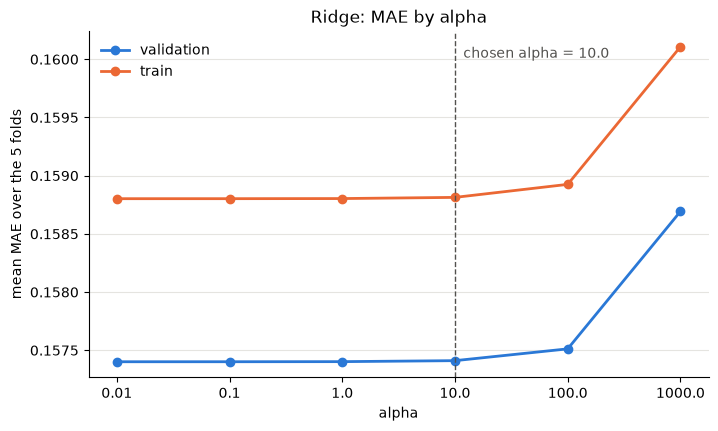

In [81]:
import matplotlib.pyplot as plt

alphas = p.load_output("baselines_alpha")
chosen = float(alphas[alphas["chosen"]]["alpha"].iloc[0])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(alphas["alpha"], alphas["val_mae"], color="#2a78d6", linewidth=2, marker="o", label="validation")
ax.plot(alphas["alpha"], alphas["train_mae"], color="#eb6834", linewidth=2, marker="o", label="train")
ax.axvline(chosen, color="#52514e", linewidth=1, linestyle="--")       # the chosen alpha
ax.annotate("chosen alpha = " + str(chosen), xy=(chosen, alphas["train_mae"].max()),
            xytext=(6, 0), textcoords="offset points", color="#52514e", va="top")
ax.set_xscale("log")                       # steps of 10 at equal distance
ax.set_xticks(alphas["alpha"])
ax.set_xticklabels([str(a) for a in alphas["alpha"]])
ax.minorticks_off()
ax.set_xlabel("alpha")
ax.set_ylabel("mean MAE over the 5 folds")
ax.set_title("Ridge: MAE by alpha")
ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

## 4.3 The scores per fold

**Check: how much do the seasons differ?** The validation scores of the 3 models in each of the 5 folds (ridge at the chosen alpha), then the MAE on the training part. Expected: the order of the 3 models is the same in every fold. The differences between seasons should be clearly smaller than the differences between the models. If not, the ladder would be luck.

**Why validation is slightly better than train.** In 4.1 the naive rule and the ridge model score a little better on the validation parts than on the training parts. The reason: seasons differ in how predictable they are, with no trend over time, and the 5 validation seasons are on average a little more predictable than the 5 seasons before them (naive MAE 0.167 against 0.170). They include 2 of the 3 most predictable seasons, 2022/23 and 2020/21. The third is 2013/14. Thin early histories do not explain it (see 4.7). The cause of the differences between seasons is not known.

In [82]:
scores = p.load_output("baselines_scores_per_fold")
alphas = p.load_output("baselines_alpha")
chosen = float(alphas[alphas["chosen"]]["alpha"].iloc[0])

# Keep the constant model, the naive rule and the ridge model at the chosen alpha.
keep = scores[(scores["model"] != "ridge") | (scores["alpha"] == chosen)]
val = keep[keep["part"] == "validation"]
train = keep[keep["part"] == "train"]

print("validation part, all 5 scores:")
show = ["model", "fold", "val_season", "n_rows"] + p.SCORES
print((val[show].round(3)).to_string(index=False))

print()
print("validation MAE, 1 column per model:")
print(val.pivot(index="val_season", columns="model", values="mae").round(4))
print()
print("training MAE, 1 column per model (the line is named after the validation season of the fold):")
print(train.pivot(index="val_season", columns="model", values="mae").round(4))
print()
print("ridge is better than naive in", int((val.pivot(index="val_season", columns="model", values="mae")
      .eval("ridge < naive")).sum()), "of 5 folds")

validation part, all 5 scores:
   model  fold val_season  n_rows   mae  rmse     r2  spearman  top10
constant     1       1819    1813 0.252 0.292 -0.000       NaN  0.106
   naive     1       1819    1813 0.171 0.218  0.440     0.678  0.450
   ridge     1       1819    1813 0.162 0.199  0.535     0.729  0.556
constant     2       1920    1655 0.252 0.291 -0.000       NaN  0.100
   naive     2       1920    1655 0.173 0.220  0.432     0.675  0.531
   ridge     2       1920    1655 0.162 0.201  0.524     0.721  0.512
constant     3       2021    2060 0.252 0.291 -0.000       NaN  0.080
   naive     3       2021    2060 0.164 0.211  0.474     0.698  0.535
   ridge     3       2021    2060 0.154 0.191  0.569     0.751  0.560
constant     4       2122    2017 0.253 0.292 -0.000       NaN  0.100
   naive     4       2122    2017 0.167 0.213  0.465     0.696  0.495
   ridge     4       2122    2017 0.156 0.193  0.561     0.752  0.520
constant     5       2223    1572 0.253 0.292 -0.000       

## 4.4 Rows with and without history

**Check: validation MAE of the 3 models, separately for athletes without a previous sprint (no_history = 1) and with one (no_history = 0).** Expected: for rows without history the constant model and the naive rule give exactly the same MAE, because the naive rule also predicts 0.5 there. The ridge model can do better on these rows: it can learn where newcomers usually finish. The rows without history are few, so their MAE moves more from fold to fold.

In [83]:
history = p.load_output("baselines_history")
print("mean and standard deviation over the 5 folds, validation part:")
print(history.round(3).to_string(index=False))

# How many rows are in each group, per fold.
scores = p.load_output("baselines_scores_per_fold")
one = scores[(scores["model"] == "constant") & (scores["part"] == "validation")]
print()
print("validation rows per fold:")
print(one.assign(n_with_history=one["n_rows"] - one["n_no_history"])
      [["fold", "val_season", "n_rows", "n_no_history", "n_with_history"]].to_string(index=False))

mean and standard deviation over the 5 folds, validation part:
   model  alpha  mae_mean  mae_std  mae_no_history_mean  mae_no_history_std  mae_with_history_mean  mae_with_history_std
constant    NaN     0.252    0.000                0.318               0.018                  0.250                 0.001
   naive    NaN     0.167    0.005                0.318               0.018                  0.162                 0.005
   ridge   10.0     0.157    0.004                0.195               0.019                  0.156                 0.004

validation rows per fold:
 fold val_season  n_rows  n_no_history  n_with_history
    1       1819    1813            62            1751
    2       1920    1655            53            1602
    3       2021    2060            60            2000
    4       2122    2017            56            1961
    5       2223    1572            57            1515


## 4.5 The ridge weights

**Check: the weights at the chosen alpha, fitted on all 10 training seasons, sorted by size.** The cell fits the model again and prints 1 weight per input.

**How to read a weight.** The inputs are scaled before the ridge step, so every input has the same spread and the weights can be compared with each other. A weight says by how much the predicted finish percentile moves when the input goes up by 1 standard deviation and all other inputs stay the same.

* Sign: a positive weight means a higher value of the input gives a higher predicted percentile, so a worse finish. A negative weight means a higher value gives a better finish.
* Size: the bigger the weight (without its sign), the more the prediction leans on this input.

**What we expect.** Positive weights for the 3 percentile features and for the last place: an athlete who was slow or finished far back in the past is predicted to finish far back again. A positive weight for the no history flag: newcomers usually finish in the back half.

**This is not causation.** A weight says what goes together with a result in the past races, not what makes it happen. 2 warnings. First, several inputs measure almost the same thing (the finish percentile of the last 3 sprints, of the last sprint, the ski percentile, the last place). The model shares the weight between them in a way that fits best, so a single weight can be small or can even have the wrong sign although the input alone is a good predictor. Second, an input can stand for something that is not in the data, for example the quality of the team or an illness.

In [84]:
alphas = p.load_output("baselines_alpha")
chosen = float(alphas[alphas["chosen"]]["alpha"].iloc[0])

weights = p.weights_table(chosen)       # fits the ridge model on all training seasons
print("alpha:", chosen, "  intercept (the prediction when every input is at its mean):",
      round(float(weights["intercept"].iloc[0]), 4))
print()
print(weights[["feature", "weight", "size"]].round(4).to_string(index=False))

# Each input alone: its correlation with the target, to compare with the sign of the weight.
df = p.load_features()
train = df[df["season"].isin(p.TRAIN_SEASONS)]
alone = train[p.FEATURES].corrwith(train[p.TARGET]).round(3)
print()
print("correlation of each input alone with the target, in the same order:")
print(alone[weights["feature"]].to_string())

alpha: 10.0   intercept (the prediction when every input is at its mean): 0.4998

          feature  weight   size
    last3_ski_pct  0.1220 0.1220
   last_place_any  0.0586 0.0586
       no_history  0.0397 0.0397
 last3_finish_pct  0.0394 0.0394
  last3_range_pct  0.0255 0.0255
  last_finish_pct -0.0108 0.0108
   n_prev_sprints -0.0045 0.0045
days_since_sprint -0.0045 0.0045
missed_prev_event  0.0031 0.0031
first_start_major  0.0025 0.0025
  days_since_race  0.0019 0.0019
     last3_misses  0.0017 0.0017
    race_days_21d -0.0015 0.0015

correlation of each input alone with the target, in the same order:
last3_ski_pct        0.710
last_place_any       0.647
no_history           0.153
last3_finish_pct     0.709
last3_range_pct      0.366
last_finish_pct      0.633
n_prev_sprints      -0.347
days_since_sprint    0.107
missed_prev_event    0.172
first_start_major    0.040
days_since_race      0.117
last3_misses         0.274
race_days_21d       -0.297


## 4.6 Sanity checks

**Check: the constant model on fold 1.** Fold 1 validates on the season 2018/19. Expected: MAE 0.252 and R2 close to 0. Why 0.252: the finish percentiles of a race are spread evenly between 0 and 1, and the mean distance from 0.5 is then about a quarter. Why R2 is close to 0: the mean of the target is 0.5 in a race without ties, so the constant model is almost exactly the model "always the mean" that R2 compares with. Athletes with the same time share the better rank, which pulls the mean a tiny bit below 0.5, so R2 is a tiny bit below 0.

In [85]:
df = p.load_features()
val_season, train_part, val_part = p.make_folds(df)[0]        # fold 1
constant = p.predict_constant(val_part)

print("validation season of fold 1:", val_season, "  rows:", len(val_part))
print("MAE :", round(float(p.mae(val_part, constant)), 3))
print("RMSE:", round(float(p.rmse(val_part, constant)), 3))
print("R2  :", round(float(p.r2(val_part, constant)), 6) + 0)
print("mean of the target in these rows:", round(float(val_part[p.TARGET].mean()), 6))

validation season of fold 1: 1819   rows: 1813
MAE : 0.252
RMSE: 0.292
R2  : -1e-06
mean of the target in these rows: 0.499788


**Check: the fill medians differ from fold to fold.** The ridge pipeline is fitted on the training part of each fold, and the medians that the fill step learned are printed. Only the 8 inputs that can be empty are interesting, the others never need a fill. Expected: the medians are not the same in all 5 folds. This proves that the filling is fitted inside each fold, on its own training rows, and not once on all rows. The cell also checks that each median equals the median of the training part computed by hand.

In [86]:
df = p.load_features()
alphas = p.load_output("baselines_alpha")
chosen = float(alphas[alphas["chosen"]]["alpha"].iloc[0])

medians = {}
by_hand_ok = True
for val_season, train_part, val_part in p.make_folds(df):
    model = p.make_ridge(chosen)
    model.fit(train_part[p.FEATURES], train_part[p.TARGET])
    learned = pd.Series(model.named_steps["fill"].statistics_, index=p.FEATURES)
    medians["validate " + val_season] = learned
    # The same medians by hand, from the training part of this fold.
    by_hand_ok = by_hand_ok and np.allclose(learned, train_part[p.FEATURES].median())

table = pd.DataFrame(medians)
can_be_empty = df[p.FEATURES].isna().any()              # inputs with at least 1 empty cell
print(table[can_be_empty].round(4))
print()
print("inputs whose median is not the same in all 5 folds:", int((table.nunique(axis=1) > 1).sum()), "of", len(table))
print("every median equals the median of its training part:", by_hand_ok)

                   validate 1819  validate 1920  validate 2021  validate 2122  validate 2223
last3_finish_pct          0.4872         0.4894         0.4880         0.4880         0.4899
last3_ski_pct             0.4865         0.4877         0.4882         0.4885         0.4910
last3_range_pct           0.4976         0.4983         0.4982         0.4964         0.4986
last3_misses              2.0000         2.0000         2.0000         2.0000         2.0000
last_finish_pct           0.4900         0.4900         0.4902         0.4896         0.4900
last_place_any           46.0000        46.0000        47.0000        47.0000        47.0000
days_since_sprint        15.0000        15.0000        15.0000        15.0000        14.0000
days_since_race           5.0000         5.0000         5.0000         5.0000         5.0000

inputs whose median is not the same in all 5 folds: 7 of 13
every median equals the median of its training part: True


**Check: no row from 2023/24 or later is loaded.** Every function of step 4 gets its rows from `p.load_features()`. That function reads the feature file and drops the test seasons before it gives the table back. Expected: the latest season is 2022/23, the latest start date is in March 2023, 0 rows of a test season, and no test season in the saved score table. The row counts must fit the split: the 5 validation parts together are the seasons 2018/19 to 2022/23.

In [87]:
df = p.load_features()
print("seasons in the table      :", sorted(df["season"].unique()))
print("latest start date         :", df["start"].max()[:10])
print("rows of a test season     :", int(df["season"].isin(p.TEST_SEASONS).sum()))

folds = p.make_folds(df)
used = pd.concat([train_part for val_season, train_part, val_part in folds] +
                 [val_part for val_season, train_part, val_part in folds])
print("seasons used by the folds :", sorted(used["season"].unique()))
print("test or history seasons in the folds:",
      int(used["season"].isin(p.TEST_SEASONS + p.HISTORY_SEASONS).sum()))

scores = p.load_output("baselines_scores_per_fold")
print("validation seasons in the saved score table:", sorted(scores["val_season"].unique()))
one = scores[(scores["model"] == "constant") & (scores["part"] == "validation")]
print("validation rows in the score table:", int(one["n_rows"].sum()),
      "  rows of these 5 seasons in the feature table:",
      int(df["season"].isin(p.VALIDATION_SEASONS).sum()))

seasons in the table      : ['1213', '1314', '1415', '1516', '1617', '1718', '1819', '1920', '2021', '2122', '2223']
latest start date         : 2023-03-18
rows of a test season     : 0
seasons used by the folds : ['1314', '1415', '1516', '1617', '1718', '1819', '1920', '2021', '2122', '2223']
test or history seasons in the folds: 0
validation seasons in the saved score table: ['1819', '1920', '2021', '2122', '2223']
validation rows in the score table: 9117   rows of these 5 seasons in the feature table: 9117


**Check: the saved tables are up to date.** The cell runs the whole of step 4 again (scores of all models, choice of alpha) and compares with the files in `outputs/`. Expected: the same chosen alpha and 0 different numbers. If this check fails, run `python pipeline.py baselines` again.

In [88]:
scores, alphas, chosen = p.find_alpha()             # the whole of step 4, again
saved_scores = p.load_output("baselines_scores_per_fold")
saved_alphas = p.load_output("baselines_alpha")

print("chosen alpha now:", chosen, "  in the saved file:", float(saved_alphas[saved_alphas["chosen"]]["alpha"].iloc[0]))
print("lines in the score table now:", len(scores), "  saved:", len(saved_scores))

numbers = p.SCORES + ["mae_no_history", "mae_with_history"]
a = scores[numbers].to_numpy(dtype=float)
b = saved_scores[numbers].to_numpy(dtype=float)
different = ~np.isclose(a, b, equal_nan=True)           # 2 empty cells count as equal
print("different numbers:", int(different.sum()), "of", different.size)

chosen alpha now: 10.0   in the saved file: 10.0
lines in the score table now: 80   saved: 80
different numbers: 0 of 560


## 4.7 Why are later seasons easier to predict?

In 4.3 the validation MAE falls from season to season. The guess: the data starts in 2012/13, so in the early seasons many athletes have a thin history (no past sprint, or fewer than 3), and a thin history is harder to predict from.

**Check: per training season, the MAE of the naive rule next to how thin the histories are.** For each season 2013/14 to 2022/23: the number of rows, the MAE of the naive rule, the share of rows with no_history = 1, and the share of rows with fewer than 3 past sprints (0, 1 or 2 valid sprints before, the no history rows included). The naive rule is used because it learns nothing: its MAE in a season does not depend on any other season. Expected if the guess is right: the early seasons have more thin histories and a higher MAE. The last lines give the MAE of the rows with a full history only (3 past sprints or more): if the guess is the whole story, that MAE should be about the same in every season.

In [89]:
df = p.load_features()
train = df[df["season"].isin(p.TRAIN_SEASONS)].copy()
train["pred"] = p.predict_naive(train)
train["error"] = (train["pred"] - train[p.TARGET]).abs()
train["thin"] = train["n_prev_sprints"] < 3            # fewer than 3 past sprints

table = pd.DataFrame({
    "rows": train.groupby("season").size(),
    "naive_mae": train.groupby("season")["error"].mean(),
    "share_no_history": train.groupby("season")["no_history"].mean(),
    "share_fewer_than_3": train.groupby("season")["thin"].mean(),
    "naive_mae_full_history": train[~train["thin"]].groupby("season")["error"].mean(),
    "naive_mae_thin_history": train[train["thin"]].groupby("season")["error"].mean(),
})
print(table.round(4))
print()
print("correlation over the 10 seasons between the naive MAE and")
print("   the share of no_history rows    :", round(table["naive_mae"].corr(table["share_no_history"]), 2))
print("   the share with fewer than 3 past:", round(table["naive_mae"].corr(table["share_fewer_than_3"]), 2))

        rows  naive_mae  share_no_history  share_fewer_than_3  naive_mae_full_history  naive_mae_thin_history
season                                                                                                       
1314    1842     0.1653            0.0423              0.1156                  0.1600                  0.2059
1415    1928     0.1724            0.0420              0.1260                  0.1673                  0.2079
1516    1730     0.1721            0.0243              0.0740                  0.1697                  0.2027
1617    1815     0.1663            0.0292              0.0722                  0.1625                  0.2157
1718    1751     0.1725            0.0183              0.0571                  0.1703                  0.2079
1819    1813     0.1713            0.0342              0.0877                  0.1654                  0.2329
1920    1655     0.1728            0.0320              0.0906                  0.1697                  0.2040
2021    20

## 4.8 How strongly does each measure repeat from 1 sprint to the next?

The ridge model leans most on the ski percentile (4.5). A reason could be that skiing speed is a stable quality of an athlete, while shooting changes more from race to race.

**Check: the correlation between the value in 1 sprint and the value in the next sprint of the same athlete.** We take the valid finishes of the training seasons, put the sprints of each athlete in time order, and pair every sprint with the next one (a pair can go over a summer break). For finish percentile, ski percentile, range percentile and misses: the correlation over all pairs, and the number of pairs. A correlation of 1 would mean the next value is known exactly, 0 would mean the last value says nothing. Expected: ski percentile the highest, misses the lowest, finish percentile in between, because the finish mixes skiing and shooting.

In [90]:
fin = p.load_fin()
fin = fin[fin["season"].isin(p.TRAIN_SEASONS)].sort_values(["IBUId", "start"])

lines = []
for name, col in [("finish percentile", "finish_pct"), ("ski percentile", "ski_pct"),
                  ("range percentile", "range_pct"), ("misses", "misses")]:
    this_sprint = fin[col]
    next_sprint = fin.groupby("IBUId")[col].shift(-1)       # the value in the athlete's next sprint
    both = this_sprint.notna() & next_sprint.notna()         # pairs where both values exist
    lines.append({"measure": name,
                  "correlation": round(this_sprint[both].corr(next_sprint[both]), 3),
                  "pairs": int(both.sum())})
print(pd.DataFrame(lines).to_string(index=False))
print()
print("athletes with at least 1 pair:", int((fin.groupby("IBUId").size() > 1).sum()))

          measure  correlation  pairs
finish percentile        0.632  17301
   ski percentile        0.830  17295
 range percentile        0.582  17293
           misses        0.171  17301

athletes with at least 1 pair: 779


## 4.9 Ridge predictions outside the range 0 to 1

The finish percentile lies between 0 and 1. The ridge model is a straight line rule and knows nothing about these limits, so it can predict a value below 0 or above 1. The predictions are not cut.

**Check: how many validation predictions are outside the range.** For each of the 5 folds the ridge pipeline is fitted on the training part at the chosen alpha (10) and predicts the validation part. Shown per fold and in total: the number of predictions below 0, the number above 1, the lowest and the highest value, and the share of all validation rows. Expected: few, and only just outside the range. The last lines show how much the validation MAE would change if the predictions were cut to the range. This is only looked at, the model is not changed.

In [91]:
df = p.load_features()
alphas = p.load_output("baselines_alpha")
chosen = float(alphas[alphas["chosen"]]["alpha"].iloc[0])

lines = []
all_pred = []
all_true = []
for val_season, train_part, val_part in p.make_folds(df):
    model = p.make_ridge(chosen)
    model.fit(train_part[p.FEATURES], train_part[p.TARGET])     # training part of the fold only
    pred = model.predict(val_part[p.FEATURES])
    lines.append({"val_season": val_season, "rows": len(pred),
                  "below_0": int((pred < 0).sum()), "above_1": int((pred > 1).sum()),
                  "lowest": pred.min(), "highest": pred.max()})
    all_pred.append(pred)
    all_true.append(val_part[p.TARGET].to_numpy())

print("alpha:", chosen)
print(pd.DataFrame(lines).round(3).to_string(index=False))

pred = np.concatenate(all_pred)
true = np.concatenate(all_true)
outside = (pred < 0) | (pred > 1)
print()
print("all validation rows       :", len(pred))
print("predictions below 0       :", int((pred < 0).sum()))
print("predictions above 1       :", int((pred > 1).sum()))
print("lowest and highest value  :", round(float(pred.min()), 3), "and", round(float(pred.max()), 3))
print("share outside the range   :", round(float(outside.mean()) * 100, 2), "%")
print()
cut = np.clip(pred, 0, 1)                                       # what cutting would do
print("MAE over all validation rows, as predicted:", round(float(np.mean(np.abs(pred - true))), 5))
print("MAE if the predictions were cut to 0..1   :", round(float(np.mean(np.abs(cut - true))), 5))

alpha: 10.0
val_season  rows  below_0  above_1  lowest  highest
      1819  1813        0        0   0.066    0.952
      1920  1655        0        0   0.060    0.970
      2021  2060        0        0   0.079    0.959
      2122  2017        0        0   0.073    0.995
      2223  1572        0        0   0.070    0.959

all validation rows       : 9117
predictions below 0       : 0
predictions above 1       : 0
lowest and highest value  : 0.06 and 0.995
share outside the range   : 0.0 %

MAE over all validation rows, as predicted: 0.1573
MAE if the predictions were cut to 0..1   : 0.1573


# Section 5: Second model family and the final choice

Ridge and a random forest, each on 2 sets of inputs. All rules below were fixed before any result was seen and are applied mechanically.

**Setup, same as section 4.** Rows: training seasons 2013/14 to 2022/23. Folds: the 5 walk forward season folds. Target: finish percentile. The test seasons are not used.

**Scores.** MAE, RMSE, R2, rank correlation per race, top 10 hit rate, on the training part and on the validation part of each fold. Every standard deviation in this lab book is the sample standard deviation (ddof = 1, divided by 5 minus 1). SE means standard error: the standard deviation of the 5 fold values divided by the square root of 5.

**The 2 input sets.**

* FULL: the 12 features plus the no history flag (13 inputs).
* NO_LOAD: FULL without `days_since_race`, `race_days_21d`, `missed_prev_event` and `first_start_major` (9 inputs).

**The 2 model families, each on both input sets.**

* Ridge: the pipeline of step 4 (median fill, StandardScaler, Ridge). Alpha grid: 0.01, 0.1, 1, 10, 100, 1000.
* Random forest: median fill, then RandomForestRegressor with 300 trees, max_features = 1/3, min_samples_leaf = 1, random_state = 42. No scaler. Depth grid: 2, 4, 6, 8, 12, 16 and None (no limit).
* Everything is fitted on the training part of each fold only.

**Completing the forest grid.** Before any selection, once, for each input set: find the depth with the lowest mean validation MAE and add the 2 depths halfway to its neighbours (best 8 gives 7 and 10, best None gives 20 and 24, and so on). No second round.

**The selection: the one standard error rule.**

1. Pool all candidates: both families, both input sets, every alpha and every depth.
2. Best = the candidate with the lowest mean validation MAE. SE = standard deviation of its 5 fold MAEs divided by the square root of 5. Threshold = best mean + SE.
3. Eligible = every candidate with a mean validation MAE at or below the threshold.
4. Among the eligible, the simplest is chosen, in this order: NO_LOAD before FULL, then ridge before forest, then for ridge the larger alpha and for the forest the smaller depth (None is the deepest).
5. Edge rule: if the chosen candidate is ridge with the largest alpha of the grid, alpha 10000 and 100000 are added for both input sets and steps 1 to 4 are repeated. Once.

The result is the final model.

**Where the numbers come from.** The command `python pipeline.py models` does all of this (about 2 minutes) and saves 10 tables in `outputs/`, all with a name that starts with `models_`. The cells below show these tables through `p.load_output`. In the tables, the depth None is written as `inf` (infinity), so that it sorts as the deepest.

## 5.1 All candidates in 1 table

**Check: every candidate, sorted by mean validation MAE, best first.** For each: the mean training MAE, then on the validation parts the mean MAE, its standard deviation and SE, and the means of the other 4 scores. The last 2 columns say if the candidate is eligible under the one standard error rule and which one is the final model. Expected: the candidates in the middle of the grids are close together, the extreme ones (very shallow forest, very large alpha) are clearly worse. The forest should fit the training rows much better than the validation rows when it is deep; ridge should be about the same on both.

In [92]:
table = p.load_output("models_candidates")
print("candidates:", len(table))
show = ["name", "train_mae_mean", "val_mae_mean", "val_mae_std", "val_mae_se",
        "val_rmse_mean", "val_r2_mean", "val_spearman_mean", "val_top10_mean",
        "eligible", "final_model"]
print(table[show].round(4).to_string(index=False))

candidates: 34
                      name  train_mae_mean  val_mae_mean  val_mae_std  val_mae_se  val_rmse_mean  val_r2_mean  val_spearman_mean  val_top10_mean  eligible  final_model
  ridge NO_LOAD alpha=0.01          0.1589        0.1574       0.0041      0.0018         0.1950       0.5524             0.7411          0.5327      True        False
   ridge NO_LOAD alpha=0.1          0.1589        0.1574       0.0041      0.0018         0.1950       0.5524             0.7411          0.5327      True        False
     ridge NO_LOAD alpha=1          0.1589        0.1574       0.0041      0.0018         0.1950       0.5524             0.7411          0.5327      True        False
     ridge FULL alpha=0.01          0.1588        0.1574       0.0041      0.0018         0.1950       0.5523             0.7413          0.5359      True        False
      ridge FULL alpha=0.1          0.1588        0.1574       0.0041      0.0018         0.1950       0.5523             0.7413          0.5359 

**The same candidates: the standard deviations of the 5 scores over the 5 folds, validation part.** Expected: similar for all candidates, because most of the spread comes from the seasons and not from the model (see 4.3).

In [93]:
table = p.load_output("models_candidates")
show = ["name"] + ["val_" + score + "_std" for score in p.SCORES]
print(table[show].round(4).to_string(index=False))

                      name  val_mae_std  val_rmse_std  val_r2_std  val_spearman_std  val_top10_std
  ridge NO_LOAD alpha=0.01       0.0041        0.0047      0.0219            0.0153         0.0222
   ridge NO_LOAD alpha=0.1       0.0041        0.0047      0.0219            0.0153         0.0222
     ridge NO_LOAD alpha=1       0.0041        0.0047      0.0219            0.0152         0.0222
     ridge FULL alpha=0.01       0.0041        0.0047      0.0220            0.0147         0.0211
      ridge FULL alpha=0.1       0.0041        0.0047      0.0220            0.0147         0.0211
        ridge FULL alpha=1       0.0041        0.0047      0.0220            0.0147         0.0211
    ridge NO_LOAD alpha=10       0.0041        0.0047      0.0219            0.0152         0.0222
       ridge FULL alpha=10       0.0041        0.0047      0.0219            0.0148         0.0211
      forest FULL depth=10       0.0039        0.0039      0.0182            0.0128         0.0146
   ridge N

## 5.2 The depth curve

**Check: mean MAE of the forest by depth, on train and on validation, for both input sets.** This look chooses nothing. Expected: the training MAE falls with every step of depth, because deeper trees can follow the training rows more closely. The validation MAE falls at first, reaches a low point and then rises slowly: beyond that depth the trees learn noise. The 2 depths added around the best depth of the grid are in the table too.

In [94]:
curve = p.load_output("models_depth_curve")
curve["depth"] = curve["value"].map(lambda v: "None" if v == np.inf else str(int(v)))
wide = curve.pivot(index="value", columns="inputs", values=["train_mae_mean", "val_mae_mean"])
wide.index = [("None" if v == np.inf else str(int(v))) for v in wide.index]
wide.index.name = "depth"
print(wide.round(4))
print()
for inputs in ["FULL", "NO_LOAD"]:
    one = curve[curve["inputs"] == inputs]
    best = one.loc[one["val_mae_mean"].idxmin()]
    print(inputs, ": lowest validation MAE at depth", best["depth"], "=", round(best["val_mae_mean"], 5))

       train_mae_mean         val_mae_mean        
inputs           FULL NO_LOAD         FULL NO_LOAD
depth                                             
2              0.1736  0.1729       0.1743  0.1735
4              0.1626  0.1622       0.1629  0.1623
6              0.1565  0.1564       0.1590  0.1588
7              0.1529  0.1530       0.1582  0.1582
8              0.1484  0.1487       0.1576  0.1577
10             0.1357  0.1364       0.1574  0.1578
12             0.1197  0.1207       0.1578  0.1581
16             0.0885  0.0896       0.1586  0.1590
None           0.0617  0.0627       0.1592  0.1595

FULL : lowest validation MAE at depth 10 = 0.15741
NO_LOAD : lowest validation MAE at depth 8 = 0.15772


**The same numbers as a picture.** Left: validation. Right: train. The 2 panels have different MAE axes, because the training MAE of a deep forest is far below everything else. The depths are placed at equal distance, they are not to scale.

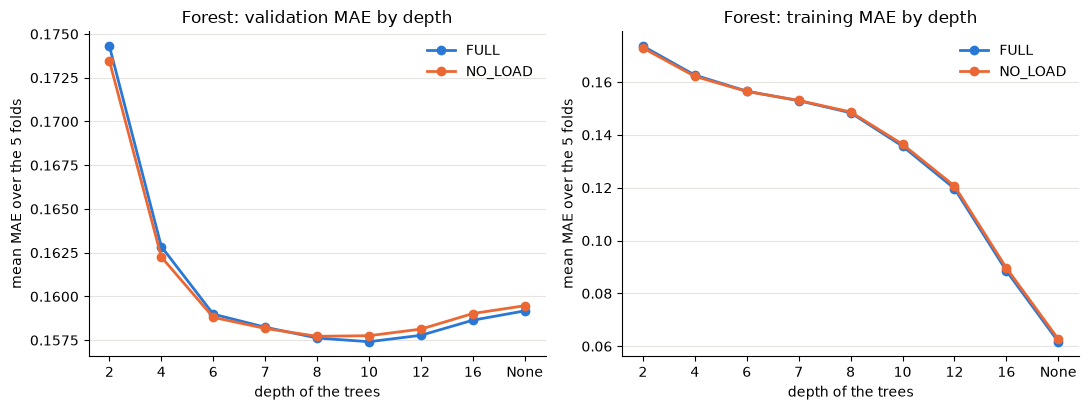

In [95]:
import matplotlib.pyplot as plt

curve = p.load_output("models_depth_curve")
colors = {"FULL": "#2a78d6", "NO_LOAD": "#eb6834"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, column, title in [(axes[0], "val_mae_mean", "Forest: validation MAE by depth"),
                          (axes[1], "train_mae_mean", "Forest: training MAE by depth")]:
    for inputs in ["FULL", "NO_LOAD"]:
        one = curve[curve["inputs"] == inputs].sort_values("value")
        labels = [("None" if v == np.inf else str(int(v))) for v in one["value"]]
        ax.plot(range(len(one)), one[column], color=colors[inputs], linewidth=2, marker="o", label=inputs)
        ax.set_xticks(range(len(one)))
        ax.set_xticklabels(labels)
    ax.set_xlabel("depth of the trees")
    ax.set_ylabel("mean MAE over the 5 folds")
    ax.set_title(title)
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 5.3 The selection, step by step

**Check: the one standard error rule, redone here from the saved fold scores.** The cell takes the score of every candidate in every fold and walks through the rule: best, SE, threshold, eligible, chosen. The SE is also computed by hand from the 5 fold MAEs of the best candidate. Then the edge rule: if the choice is ridge with the largest alpha of the grid, the candidates with alpha 10000 and 100000 are added and the rule is applied a second time. Expected: the same final model as in the saved table `models_selection`.

In [96]:
scores = p.load_output("models_scores_per_fold")


def show_round(scores, title):
    """Apply the rule to the given scores and print every step."""
    table = p.candidate_table(scores)
    choice = p.one_se_rule(table)
    folds = p.fold_values(scores, choice["best"])          # the 5 fold MAEs of the best
    print(title)
    print("  1. candidates in the pool   :", len(table))
    print("  2. best (lowest mean)       :", choice["best"], " mean:", round(choice["best_mean"], 5))
    print("     its 5 fold MAEs          :", folds.round(4))
    print("     SE by hand = std / sqrt(5):", round(folds.std(ddof=1) / np.sqrt(5), 5),
          "  from the function:", round(choice["se"], 5))
    print("     threshold = mean + SE    :", round(choice["threshold"], 5))
    eligible = table[table["name"].isin(choice["eligible"])]
    print("  3. eligible candidates      :", len(eligible), "of", len(table))
    print("  4. the eligible, simplest first (the first line is chosen):")
    print(p.simplest_first(eligible)[["name", "val_mae_mean"]].round(5).to_string(index=False))
    print("     CHOSEN:", choice["chosen"])
    return table, choice


table, choice = show_round(scores[scores["round"] != "edge rule"], "FIRST ROUND (without the edge rule alphas)")
chosen = table.set_index("name").loc[choice["chosen"]]
edge = (chosen["family"] == "ridge") and (chosen["value"] == max(p.ALPHA_GRID))
print()
print("  5. is the choice ridge with the largest alpha of the grid?", bool(edge))
if edge:
    print()
    table, choice = show_round(scores, "SECOND ROUND (alpha 10000 and 100000 added for both input sets)")
print()
print("THE FINAL MODEL          :", choice["chosen"])
print("in the saved table       :", p.load_output("models_selection")["final_model"].iloc[0])
final = table.set_index("name").loc[choice["chosen"]]
print("its mean validation MAE  :", round(final["val_mae_mean"], 5), "  standard deviation:", round(final["val_mae_std"], 5))

FIRST ROUND (without the edge rule alphas)
  1. candidates in the pool   : 30
  2. best (lowest mean)       : ridge NO_LOAD alpha=0.01  mean: 0.15739
     its 5 fold MAEs          : [0.1616 0.162  0.1541 0.1557 0.1536]
     SE by hand = std / sqrt(5): 0.00184   from the function: 0.00184
     threshold = mean + SE    : 0.15924
  3. eligible candidates      : 25 of 30
  4. the eligible, simplest first (the first line is chosen):
                    name  val_mae_mean
ridge NO_LOAD alpha=1000       0.15868
 ridge NO_LOAD alpha=100       0.15751
  ridge NO_LOAD alpha=10       0.15740
   ridge NO_LOAD alpha=1       0.15739
 ridge NO_LOAD alpha=0.1       0.15739
ridge NO_LOAD alpha=0.01       0.15739
  forest NO_LOAD depth=6       0.15881
  forest NO_LOAD depth=7       0.15817
  forest NO_LOAD depth=8       0.15772
 forest NO_LOAD depth=10       0.15776
 forest NO_LOAD depth=12       0.15813
 forest NO_LOAD depth=16       0.15902
   ridge FULL alpha=1000       0.15869
    ridge FULL alpha=1

**Check: the same rule inside each family and input set alone.** This does not change the choice. For each of the 4 groups: the candidate with the lowest mean, and the one the one standard error rule would pick if only this group existed (ridge: the largest eligible alpha, forest: the smallest eligible depth). Expected: the pick is simpler than the lowest mean candidate, and only a little worse.

In [97]:
groups = p.load_output("models_groups")
print(groups.round(5).to_string(index=False))

family  inputs              lowest_mean  lowest_mean_mae      se  threshold              one_se_pick  one_se_pick_mae
 ridge    FULL    ridge FULL alpha=0.01          0.15740 0.00184    0.15925    ridge FULL alpha=1000          0.15869
 ridge NO_LOAD ridge NO_LOAD alpha=0.01          0.15739 0.00184    0.15924 ridge NO_LOAD alpha=1000          0.15868
forest    FULL     forest FULL depth=10          0.15741 0.00175    0.15917      forest FULL depth=6          0.15899
forest NO_LOAD   forest NO_LOAD depth=8          0.15772 0.00186    0.15958   forest NO_LOAD depth=6          0.15881


## 5.4 With and without the load features

The load hypothesis: how much and how recently an athlete raced (the 4 load features) helps to predict the sprint.

**Check: for each family, the best FULL candidate against the best NO_LOAD candidate.** Shown: the 2 mean validation MAEs with their SE, the difference FULL minus NO_LOAD in each fold, the mean difference, and the SE of the difference (sample standard deviation of the 5 fold differences, divided by the square root of 5). A value below 0 means FULL is better, so the load features help. Expected if the load features help: the difference is below 0 in most folds and its mean is clearly further from 0 than its SE. If the mean difference is smaller than its SE, the data cannot tell the 2 input sets apart.

In [98]:
comparisons = p.load_output("models_comparisons")
load = comparisons[comparisons["comparison"].str.startswith("load")]
for index, line in load.iterrows():
    folds = [line["diff_fold_" + str(number)] for number in range(1, 6)]
    print(line["comparison"])
    print("   FULL   :", line["a"], " mean MAE:", round(line["a_mean"], 5), " SE:", round(line["a_se"], 5))
    print("   NO_LOAD:", line["b"], " mean MAE:", round(line["b_mean"], 5), " SE:", round(line["b_se"], 5))
    print("   difference in each fold   :", [round(value, 5) for value in folds])
    print("   folds where FULL is better:", sum(value < 0 for value in folds), "of 5")
    print("   mean difference           :", round(line["diff_mean"], 5))
    print("   SE of the difference      :", round(line["diff_se"], 5))
    print("   mean difference / its SE  :", round(line["diff_mean"] / line["diff_se"], 2))
    print()

load, ridge: FULL minus NO_LOAD
   FULL   : ridge FULL alpha=0.01  mean MAE: 0.1574  SE: 0.00184
   NO_LOAD: ridge NO_LOAD alpha=0.01  mean MAE: 0.15739  SE: 0.00184
   difference in each fold   : [8e-05, -2e-05, -2e-05, -0.0001, 0.00011]
   folds where FULL is better: 3 of 5
   mean difference           : 1e-05
   SE of the difference      : 4e-05
   mean difference / its SE  : 0.22

load, forest: FULL minus NO_LOAD
   FULL   : forest FULL depth=10  mean MAE: 0.15741  SE: 0.00175
   NO_LOAD: forest NO_LOAD depth=8  mean MAE: 0.15772  SE: 0.00186
   difference in each fold   : [-0.00112, -0.00011, 6e-05, -0.00029, -9e-05]
   folds where FULL is better: 4 of 5
   mean difference           : -0.00031
   SE of the difference      : 0.00021
   mean difference / its SE  : -1.48



## 5.5 Ridge against forest, per fold

**Check: the best ridge candidate against the best forest candidate (lowest mean validation MAE of each family).** Shown: the validation MAE of both in each fold, the difference ridge minus forest, its mean and its SE. A value below 0 means ridge is better. Expected: we do not know in advance. A forest can find rules that a straight line model cannot (thresholds, inputs that only matter together). If the forest is not better, such rules are not needed for these inputs, or the data is too noisy to show them.

In [99]:
comparisons = p.load_output("models_comparisons")
scores = p.load_output("models_scores_per_fold")
line = comparisons[comparisons["comparison"] == "ridge minus forest"].iloc[0]

val = scores[(scores["part"] == "validation") & scores["name"].isin([line["a"], line["b"]])]
wide = val.pivot(index="val_season", columns="name", values="mae")[[line["a"], line["b"]]]
wide["ridge minus forest"] = wide[line["a"]] - wide[line["b"]]
print(wide.round(5))
print()
print("mean MAE, best ridge :", round(line["a_mean"], 5), " SE:", round(line["a_se"], 5))
print("mean MAE, best forest:", round(line["b_mean"], 5), " SE:", round(line["b_se"], 5))
print("mean difference      :", round(line["diff_mean"], 5), "  SE of the difference:", round(line["diff_se"], 5))
print("folds where ridge is better:", int((wide["ridge minus forest"] < 0).sum()), "of 5")

print()
print("the other scores of the 2 candidates, mean over the 5 folds, validation part:")
table = p.load_output("models_candidates")
both = table[table["name"].isin([line["a"], line["b"]])]
print(both[["name", "val_mae_mean", "val_rmse_mean", "val_r2_mean", "val_spearman_mean", "val_top10_mean"]]
      .round(4).to_string(index=False))

name        ridge NO_LOAD alpha=0.01  forest FULL depth=10  ridge minus forest
val_season                                                                    
1819                         0.16161               0.16054             0.00106
1920                         0.16203               0.16242            -0.00039
2021                         0.15407               0.15514            -0.00107
2122                         0.15570               0.15593            -0.00022
2223                         0.15356               0.15303             0.00053

mean MAE, best ridge : 0.15739  SE: 0.00184
mean MAE, best forest: 0.15741  SE: 0.00175
mean difference      : -2e-05   SE of the difference: 0.00037
folds where ridge is better: 3 of 5

the other scores of the 2 candidates, mean over the 5 folds, validation part:
                    name  val_mae_mean  val_rmse_mean  val_r2_mean  val_spearman_mean  val_top10_mean
ridge NO_LOAD alpha=0.01        0.1574         0.1950       0.5524             

## 5.6 Rows with and without history

**Check: validation MAE of the best ridge and the best forest, separately for athletes without a previous sprint (no_history = 1) and with one.** Mean and standard deviation over the 5 folds. Expected: both are clearly worse on rows without history, where almost every input is empty and was filled. The forest could be better there, because a tree can make a separate rule for the newcomers. The no history groups are small (53 to 62 rows per fold), so their numbers move a lot.

In [100]:
history = p.load_output("models_history")
print(history.round(4).to_string(index=False))

                    name  val_mae_mean  val_mae_std  val_mae_no_history_mean  val_mae_no_history_std  val_mae_with_history_mean  val_mae_with_history_std
ridge NO_LOAD alpha=0.01        0.1574       0.0041                   0.1952                  0.0199                     0.1561                    0.0044
    forest FULL depth=10        0.1574       0.0039                   0.1878                  0.0178                     0.1564                    0.0046


## 5.7 The learning curve

**Check: does more data still help?** For the final model and for the best candidate of the other family: the model is trained on 20, 40, 60, 80 and 100 % of the training rows of each fold (a random subset with a fixed seed) and scored on the same validation part. Shown: the mean training MAE and the mean validation MAE over the 5 folds. This look chooses nothing. Expected: the validation MAE falls when the share grows and flattens out. If it is flat at the end, more seasons of the same kind of data would not help much. The gap between the 2 lines shows how much the model fits the training rows better than new rows.

**What the result shows.** For the final ridge model the training MAE falls with more data, like the validation MAE. The reason: alpha is fixed at 1000, and with fewer rows the same alpha is a relatively stronger penalty. The weights are pulled harder towards 0, so the model fits even its own training rows less well. Its validation MAE is still falling a little at 100 %. For the forest the training MAE rises with more rows, because a forest can follow few rows more closely than many. The validation MAE of the forest is flat from 60 % on (0.1575, 0.1574, 0.1574): more data of this kind would not help it.

In [101]:
curve = p.load_output("models_learning_curve")
for role in ["final model", "best of the other family"]:
    one = curve[curve["role"] == role]
    print(role, ":", one["name"].iloc[0])
    print(one[["share", "n_train_rows", "train_mae", "val_mae"]].round(4).to_string(index=False))
    last_step = one["val_mae"].iloc[-1] - one["val_mae"].iloc[-2]
    print("   change of the validation MAE from 80 % to 100 %:", round(last_step, 5))
    print()

final model : ridge NO_LOAD alpha=1000
 share  n_train_rows  train_mae  val_mae
   0.2        2547.4     0.1643   0.1630
   0.4        5094.8     0.1617   0.1603
   0.6        7642.0     0.1606   0.1594
   0.8       10189.4     0.1604   0.1589
   1.0       12736.8     0.1602   0.1587
   change of the validation MAE from 80 % to 100 %: -0.00026

best of the other family : forest FULL depth=10
 share  n_train_rows  train_mae  val_mae
   0.2        2547.4     0.1078   0.1589
   0.4        5094.8     0.1208   0.1579
   0.6        7642.0     0.1279   0.1575
   0.8       10189.4     0.1326   0.1574
   1.0       12736.8     0.1357   0.1574
   change of the validation MAE from 80 % to 100 %: 4e-05



**The same numbers as a picture.** 1 panel per model. The 2 panels have different MAE axes.

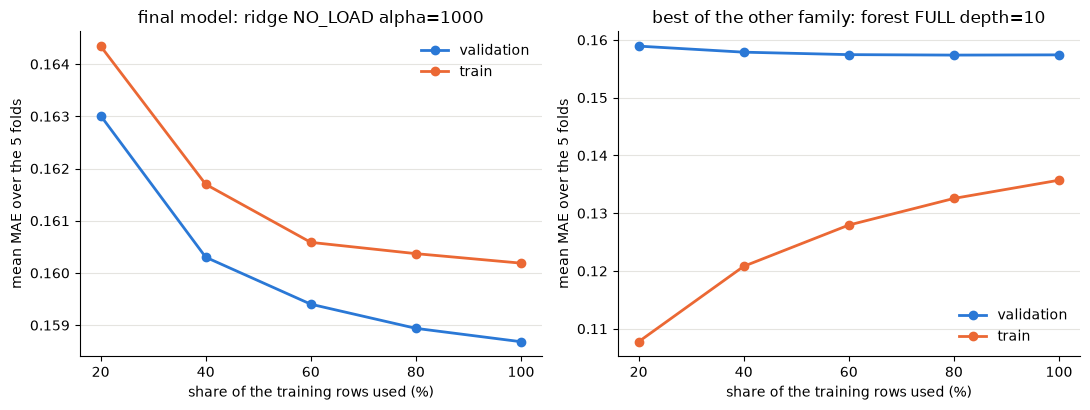

In [102]:
import matplotlib.pyplot as plt

curve = p.load_output("models_learning_curve")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, role in zip(axes, ["final model", "best of the other family"]):
    one = curve[curve["role"] == role]
    ax.plot(one["share"] * 100, one["val_mae"], color="#2a78d6", linewidth=2, marker="o", label="validation")
    ax.plot(one["share"] * 100, one["train_mae"], color="#eb6834", linewidth=2, marker="o", label="train")
    ax.set_xticks(one["share"] * 100)
    ax.set_xlabel("share of the training rows used (%)")
    ax.set_ylabel("mean MAE over the 5 folds")
    ax.set_title(role + ": " + one["name"].iloc[0])
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 5.8 The feature importances of the forest

**Check: `feature_importances_` of the forest with the FULL inputs, at its depth with the lowest mean validation MAE, fitted on all 10 training seasons, sorted.** The cell fits the forest again. An importance says which share of the total error reduction inside the trees came from splits on this input. The 13 values add up to 1.

**This is a first look only.** 2 known weaknesses. First, this measure favours inputs with many different values (a percentile has thousands, a flag has 2): such an input offers more places to split, so it is picked more often. Second, it splits the credit between inputs that overlap: when 2 inputs carry almost the same information, each tree takes one or the other, and both look less important than the information really is. And it is computed on the training rows, not on new rows. Permutation importance comes in step 6.

Expected: the past results (ski percentile, finish percentile, last place) at the top, the flags at the bottom.

In [103]:
candidates = p.load_output("models_candidates")
forest_full = candidates[(candidates["family"] == "forest") & (candidates["inputs"] == "FULL")]
depth = forest_full.loc[forest_full["val_mae_mean"].idxmin(), "value"]

table = p.importance_table(depth)           # fits the forest on all training seasons
table["different_values"] = [p.load_features()[name].nunique() for name in table["feature"]]
print("forest, FULL inputs, depth:", "None" if depth == np.inf else int(depth))
print(table[["feature", "importance", "different_values"]].round(4).to_string(index=False))
print()
print("sum of the importances:", round(float(table["importance"].sum()), 4))
print("share of the 4 load features together:",
      round(float(table[table["feature"].isin(p.LOAD_FEATURES)]["importance"].sum()), 4))

forest, FULL inputs, depth: 10
          feature  importance  different_values
    last3_ski_pct      0.3157             18765
 last3_finish_pct      0.3053             18838
   last_place_any      0.1630               122
  last_finish_pct      0.0907              3327
  last3_range_pct      0.0434             18833
   n_prev_sprints      0.0236                21
     last3_misses      0.0143                31
  days_since_race      0.0132               187
days_since_sprint      0.0130               164
    race_days_21d      0.0091                 9
       no_history      0.0043                 2
first_start_major      0.0025                 2
missed_prev_event      0.0019                 2

sum of the importances: 1.0
share of the 4 load features together: 0.0267


## 5.9 Sanity checks

**Check: ridge with the FULL inputs at alpha 10 gives the numbers of step 4.** It is the same model as the ridge of section 4, scored by the new code of step 5. Expected: every score in every fold and part equals the saved step 4 value, 0 different numbers.

In [104]:
new = p.load_output("models_scores_per_fold")
old = p.load_output("baselines_scores_per_fold")
new = new[new["name"] == "ridge FULL alpha=10"].sort_values(["fold", "part"])
old = old[(old["model"] == "ridge") & (old["alpha"] == 10)].sort_values(["fold", "part"])

numbers = p.SCORES + ["mae_no_history", "mae_with_history"]
a = new[numbers].to_numpy(dtype=float)
b = old[numbers].to_numpy(dtype=float)
print("lines compared (5 folds x 2 parts):", len(new), "and", len(old))
print("different numbers:", int((~np.isclose(a, b)).sum()), "of", a.size)
print("largest difference:", float(np.abs(a - b).max()))
print("mean validation MAE, step 5:", round(float(new[new["part"] == "validation"]["mae"].mean()), 5),
      "  step 4:", round(float(old[old["part"] == "validation"]["mae"].mean()), 5))

lines compared (5 folds x 2 parts): 10 and 10
different numbers: 0 of 70
largest difference: 0.0
mean validation MAE, step 5: 0.15741   step 4: 0.15741


**Check: all forest predictions lie between 0 and 1.** A tree predicts the mean of the targets of the training rows in a leaf, and a forest takes the mean over its trees. A mean of numbers between 0 and 1 cannot leave that range, so this must hold for every forest. The cell checks it on 4 forests in all 5 folds, on the training part and on the validation part: for each input set the depth with the lowest mean validation MAE and the depth None. Expected: 0 predictions outside.

In [105]:
df = p.load_features()
candidates = p.load_output("models_candidates")
forests = candidates[candidates["family"] == "forest"]

chosen = []
for inputs in p.INPUT_SETS:
    group = forests[forests["inputs"] == inputs]
    chosen.append((inputs, group.loc[group["val_mae_mean"].idxmin(), "value"]))     # best depth
    chosen.append((inputs, p.NO_LIMIT))                                             # depth None

lines = []
for inputs, depth in chosen:
    columns = p.INPUT_SETS[inputs]
    outside = 0
    lowest = 1.0
    highest = 0.0
    for val_season, train_part, val_part in p.make_folds(df):
        model = p.make_forest(depth)
        model.fit(train_part[columns], train_part[p.TARGET])
        for rows in [train_part, val_part]:
            pred = model.predict(rows[columns])
            outside = outside + int(((pred < 0) | (pred > 1)).sum())
            lowest = min(lowest, float(pred.min()))
            highest = max(highest, float(pred.max()))
    lines.append({"forest": p.candidate_name("forest", inputs, depth), "predictions_outside": outside,
                  "lowest": round(lowest, 4), "highest": round(highest, 4)})
print(pd.DataFrame(lines).to_string(index=False))

                   forest  predictions_outside  lowest  highest
     forest FULL depth=10                    0  0.0365   0.9625
   forest FULL depth=None                    0  0.0068   0.9865
   forest NO_LOAD depth=8                    0  0.0534   0.9510
forest NO_LOAD depth=None                    0  0.0081   0.9880


**Check: a second run gives identical numbers.** The forest uses random numbers (which rows and which inputs each tree sees), fixed by `random_state = 42`. The cell scores 3 candidates again on all 5 folds and compares with the saved file: the final model, the best forest, and the forest NO_LOAD with depth None. Expected: the same numbers. "The same" means equal to at least 12 decimals. The numbers are not equal to the very last digit, for 2 reasons that have nothing to do with the model. First, the trees of a forest are computed on several processor cores at once, and the order in which their predictions are added up can change from run to run, which moves the 16th decimal. Second, saving a number in a file and reading it back can also move the last digit. The ridge model has no such effect inside one run of the command.

The whole command `python pipeline.py models` was also run twice in a row when this section was built. The final model, every eligible flag and all names were identical in the 10 saved tables. The largest difference between 2 numbers was 0.0000000000000002.

In [106]:
saved = p.load_output("models_scores_per_fold")
candidates = p.load_output("models_candidates")
final = candidates[candidates["final_model"]]["name"].iloc[0]
best_forest = p.best_name(candidates, family="forest")
names = [final, best_forest, "forest NO_LOAD depth=None"]

again = []
for name in names:
    line = candidates.set_index("name").loc[name]
    again.append((line["family"], line["inputs"], line["value"]))
fresh = p.score_candidates(again)                 # fits and scores these 3 candidates again

numbers = p.SCORES + ["mae_no_history", "mae_with_history"]
keys = ["name", "fold", "part"]
both = fresh.merge(saved, on=keys, suffixes=("_now", "_saved"))
print("lines compared:", len(both), "(3 candidates x 5 folds x 2 parts)")
for name in names:
    one = both[both["name"] == name]
    a = one[[n + "_now" for n in numbers]].to_numpy(dtype=float)
    b = one[[n + "_saved" for n in numbers]].to_numpy(dtype=float)
    difference = np.abs(a - b)
    print(f"{name:<28} numbers that differ by more than 0.000000000001: "
          f"{int((difference > 1e-12).sum())} of {a.size}   largest difference: {difference.max():.1e}")

  fold 1 of 5 done


  fold 2 of 5 done


  fold 3 of 5 done


  fold 4 of 5 done


  fold 5 of 5 done
lines compared: 30 (3 candidates x 5 folds x 2 parts)
ridge NO_LOAD alpha=1000     numbers that differ by more than 0.000000000001: 0 of 70   largest difference: 8.3e-17
forest FULL depth=10         numbers that differ by more than 0.000000000001: 0 of 70   largest difference: 1.1e-16
forest NO_LOAD depth=None    numbers that differ by more than 0.000000000001: 0 of 70   largest difference: 1.1e-16


**Check: no row from 2023/24 or later is loaded.** Every function of step 5 gets its rows from `p.load_features()`, which drops the test seasons before it gives the table back. Expected: the latest season is 2022/23, 0 rows of a test season, only the 5 validation seasons in the saved score table, and the row counts of the folds equal those of step 4.

In [107]:
df = p.load_features()
print("seasons in the table        :", sorted(df["season"].unique()))
print("latest start date           :", df["start"].max()[:10])
print("rows of a test season       :", int(df["season"].isin(p.TEST_SEASONS).sum()))

scores = p.load_output("models_scores_per_fold")
print("validation seasons in the saved score table:", sorted(scores["val_season"].unique()))
one = scores[scores["name"] == scores["name"].iloc[0]]
print()
print("rows per fold and part in the score table (the same for every candidate):")
print(one.pivot(index="val_season", columns="part", values="n_rows"))
print("different row counts between candidates:",
      int((scores.groupby(["fold", "part"])["n_rows"].nunique() > 1).sum()))
print("validation rows in total:", int(one[one["part"] == "validation"]["n_rows"].sum()),
      "  rows of the 5 validation seasons in the feature table:",
      int(df["season"].isin(p.VALIDATION_SEASONS).sum()))

seasons in the table        : ['1213', '1314', '1415', '1516', '1617', '1718', '1819', '1920', '2021', '2122', '2223']
latest start date           : 2023-03-18
rows of a test season       : 0
validation seasons in the saved score table: ['1819', '1920', '2021', '2122', '2223']

rows per fold and part in the score table (the same for every candidate):
part        train  validation
val_season                   
1819         9066        1813
1920        10879        1655
2021        12534        2060
2122        14594        2017
2223        16611        1572
different row counts between candidates: 0
validation rows in total: 9117   rows of the 5 validation seasons in the feature table: 9117


# Section 6